In [1]:
from pathlib import Path

print("Current notebook directory:")
print(Path.cwd())

Current notebook directory:
C:\Users\Admin\Desktop\DriverMonitoringSystem


In [2]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Scripts\python.exe

Python version:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


# Driver Monitoring System for Driver Distraction Detection

## Image Processing, Ear Annotation and YOLO-Based Detection

This notebook implements the complete image-processing pipeline for a
Driver Monitoring System (DMS), including:

1. Dataset inspection
2. Image acquisition
3. Color-space conversion
4. Pixel manipulation
5. Basic image operations
6. Image filtering
7. Canny edge detection
8. Thresholding
9. Morphological operations
10. Histogram enhancement
11. Ear annotation and YOLO dataset preparation
12. Contour and ROI analysis
13. YOLO-based ear detection preparation

In [3]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import shutil
from collections import Counter

In [4]:
PROJECT_ROOT = Path.cwd()

In [5]:
IMAGES_DIR = PROJECT_ROOT / "Images"

In [6]:
DATASET_DIR = PROJECT_ROOT / "dataset"

In [7]:
SPLIT_DIR = PROJECT_ROOT / "dataset_split"

In [8]:
EAR_DATASET_DIR = PROJECT_ROOT / "ear_dataset"

In [10]:
PROCESSED_DIR = PROJECT_ROOT / "processed_images"

In [11]:
RESULTS_DIR = PROJECT_ROOT / "results"

In [12]:
MODELS_DIR = PROJECT_ROOT / "models"

In [13]:
for directory in [
    PROCESSED_DIR,
    RESULTS_DIR,
    MODELS_DIR,
    SPLIT_DIR,
    EAR_DATASET_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

In [14]:
print("Project Root:")
print(PROJECT_ROOT)

Project Root:
C:\Users\Admin\Desktop\DriverMonitoringSystem


In [15]:
for path in PROJECT_ROOT.iterdir():
    print(path.name)

.ipynb_checkpoints
.venv
app
dataset
dataset_split
Driver_Monitoring_System.ipynb.ipynb
ear_dataset
Images
models
processed_images
results
scripts


In [16]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

In [17]:
all_images = []

In [18]:
for path in IMAGES_DIR.rglob("*"):
    if path.suffix.lower() in image_extensions:
        all_images.append(path)

In [19]:
print("Total images found:", len(all_images))

Total images found: 287


In [20]:
class_counts = Counter()

In [21]:
for image_path in all_images:
    class_name = image_path.parent.name
    class_counts[class_name] += 1

In [22]:
print("Dataset distribution:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Dataset distribution:
front: 51
side angles: 236


In [23]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

<BarContainer object of 2 artists>

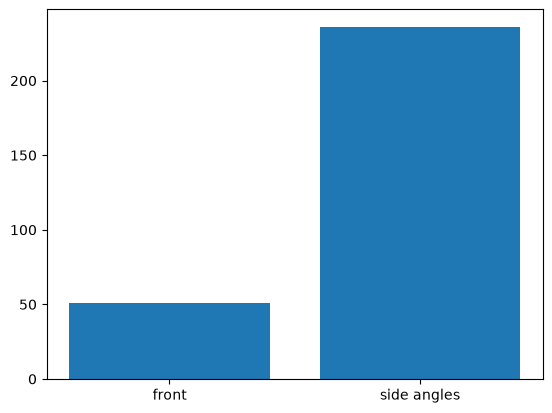

In [24]:
plt.bar(
    class_counts.keys(),
    class_counts.values()
)

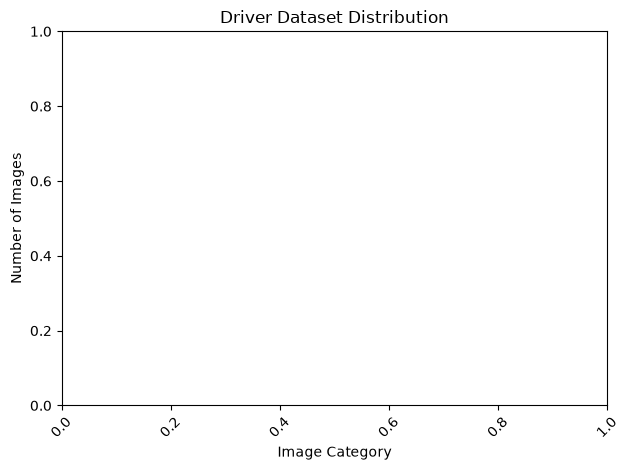

In [25]:
plt.xlabel("Image Category")
plt.ylabel("Number of Images")
plt.title("Driver Dataset Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

<BarContainer object of 2 artists>

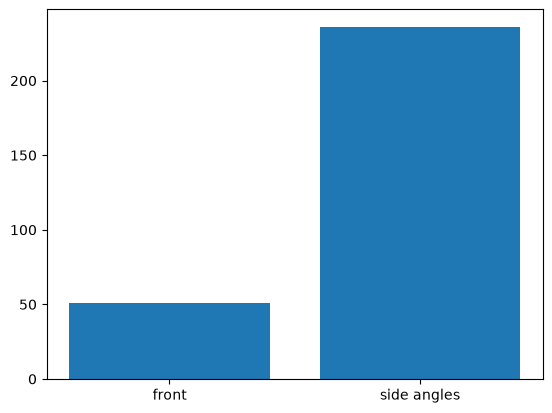

In [27]:
plt.bar(
    class_counts.keys(),
    class_counts.values()
)


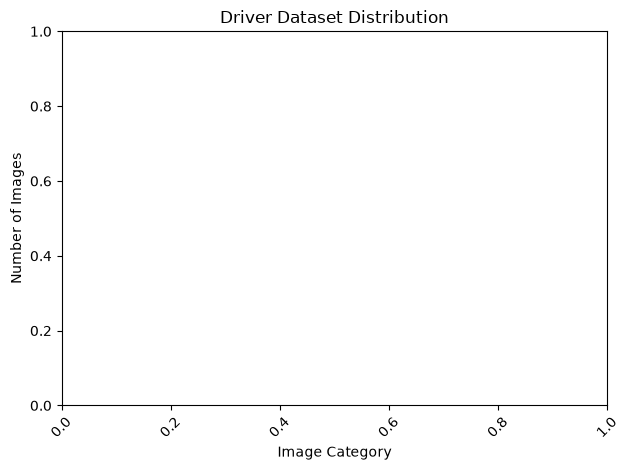

In [28]:
plt.xlabel("Image Category")
plt.ylabel("Number of Images")
plt.title("Driver Dataset Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "dataset_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [29]:
from pathlib import Path

print("Project Root:")
print(PROJECT_ROOT)

print("\nImages directory:")
print(IMAGES_DIR)

print("\nDoes Images folder exist?")
print(IMAGES_DIR.exists())

print("\nContents of Images:")
if IMAGES_DIR.exists():
    for item in IMAGES_DIR.iterdir():
        print(item)
else:
    print("Images folder not found")

Project Root:
C:\Users\Admin\Desktop\DriverMonitoringSystem

Images directory:
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images

Does Images folder exist?
True

Contents of Images:
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\side angles


In [30]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

all_images = [
    path
    for path in IMAGES_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

print("Total images found:", len(all_images))

print("\nFirst 10 images:")

for path in all_images[:10]:
    print(path)

Total images found: 287

First 10 images:
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4159.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4164.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4169.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4175.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4180.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4181.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4186 (1).JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4186.JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4191 (1).JPG
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4191.JPG


In [31]:
from collections import Counter
import matplotlib.pyplot as plt

class_counts = Counter()

for image_path in all_images:
    category = image_path.parent.name
    class_counts[category] += 1

print("Dataset distribution:")

for category, count in class_counts.items():
    print(f"{category}: {count}")

Dataset distribution:
front: 51
side angles: 236


In [32]:
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [33]:
categories=list(class_counts.keys())

In [34]:
counts=list(class_counts.values())

<BarContainer object of 2 artists>

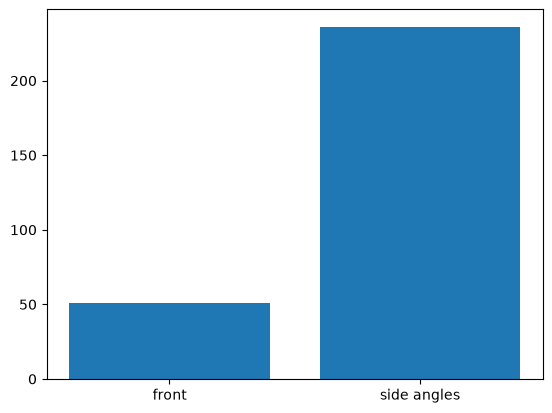

In [35]:
plt.bar( categories,counts)

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

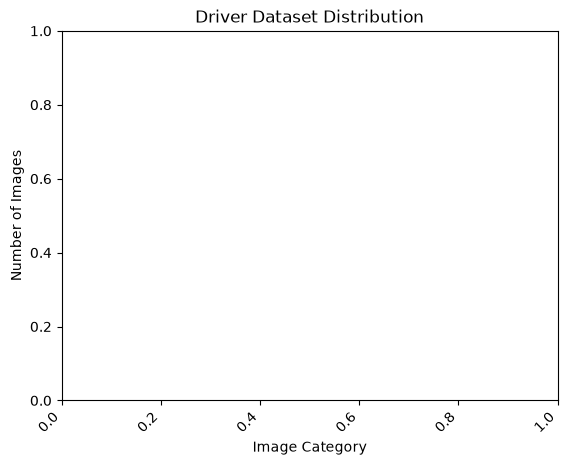

In [38]:
plt.xlabel("Image Category")
plt.ylabel("Number of Images")
plt.title("Driver Dataset Distribution")

plt.xticks(
    rotation=45,
    ha="right")

In [39]:
plt.tight_layout()

plt.show()

<Figure size 640x480 with 0 Axes>

In [40]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nProject folders:")
for item in Path.cwd().iterdir():
    print(item.name)

print("\nSearching for image files...")

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

all_images = []

for path in Path.cwd().rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        all_images.append(path)

print("\nTotal image files found:", len(all_images))

print("\nFirst 20 image paths:")

for path in all_images[:20]:
    print(path)

Current working directory:
C:\Users\Admin\Desktop\DriverMonitoringSystem

Project folders:
.ipynb_checkpoints
.venv
app
dataset
dataset_split
Driver_Monitoring_System.ipynb.ipynb
ear_dataset
Images
models
processed_images
results
scripts

Searching for image files...

Total image files found: 3632

First 20 image paths:
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Lib\site-packages\ipykernel\resources\logo-32x32.png
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Lib\site-packages\ipykernel\resources\logo-64x64.png
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Lib\site-packages\matplotlib\mpl-data\images\back.png
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Lib\site-packages\matplotlib\mpl-data\images\back_large.png
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Lib\site-packages\matplotlib\mpl-data\images\filesave.png
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Lib\site-packages\matplotlib\mpl-data\images\filesave_large.png
C:\Users\Admin\Desktop\D

In [41]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Search only actual project image folders
search_folders = [
    PROJECT_ROOT / "Images",
    PROJECT_ROOT / "dataset",
    PROJECT_ROOT / "dataset_split"
]

all_images = []

for folder in search_folders:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in image_extensions:
                all_images.append(path)

print("Total project dataset images:", len(all_images))

print("\nImages by main folder:")

for folder in search_folders:
    if folder.exists():
        count = sum(
            1
            for path in folder.rglob("*")
            if path.is_file()
            and path.suffix.lower() in image_extensions
        )
        print(f"{folder.name}: {count}")

Total project dataset images: 861

Images by main folder:
Images: 287
dataset: 287
dataset_split: 287


In [42]:
images_dir = PROJECT_ROOT / "Images"

print("Images folder:")
print(images_dir)

print("\nSubfolders:")

for item in images_dir.iterdir():
    print(item.name)

Images folder:
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images

Subfolders:
front
side angles


In [43]:
from collections import Counter

category_counts = Counter()

for image_path in all_images:
    relative_path = image_path.relative_to(PROJECT_ROOT)

    # First folder after project root
    category = relative_path.parts[0]

    category_counts[category] += 1

print("Image distribution:")
print()

for category, count in category_counts.items():
    print(f"{category}: {count}")

Image distribution:

Images: 287
dataset: 287
dataset_split: 287


In [44]:
from pathlib import Path

images_dir = PROJECT_ROOT / "Images"

image_files = [
    p for p in images_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Images folder total:", len(image_files))

print("\nImages by immediate parent folder:")

parent_counts = Counter(
    p.parent.name for p in image_files
)

for name, count in parent_counts.items():
    print(f"{name}: {count}")

Images folder total: 287

Images by immediate parent folder:
front: 51
side angles: 236


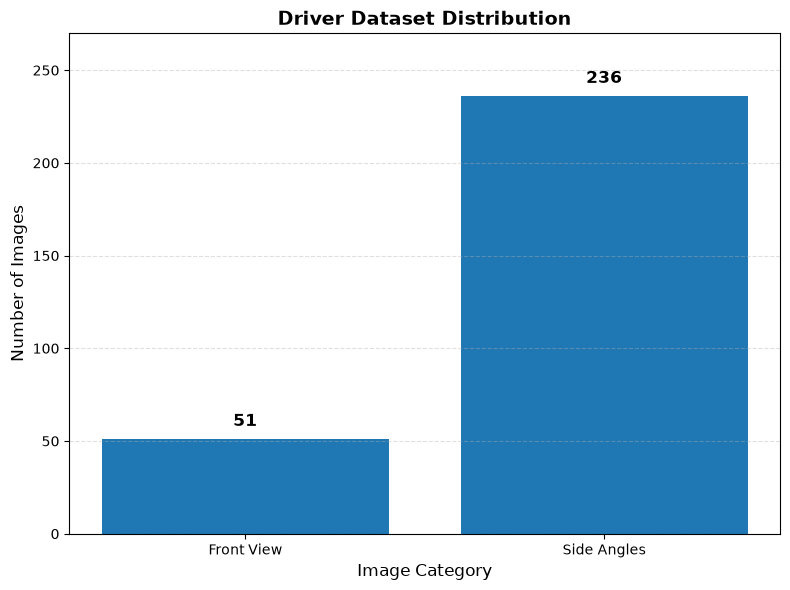

Graph saved to: C:\Users\Admin\Desktop\DriverMonitoringSystem\results\driver_dataset_distribution.png


In [46]:
import matplotlib.pyplot as plt

# Verified dataset counts
categories = ["Front View", "Side Angles"]
counts = [51, 236]

# Create figure
plt.figure(figsize=(8, 6))

bars = plt.bar(
    categories,
    counts
)

# Add values above bars
for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# Labels and title
plt.xlabel("Image Category", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

plt.title(
    "Driver Dataset Distribution",
    fontsize=14,
    fontweight="bold"
)

# Set y-axis
plt.ylim(0, 270)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

# Save graph
output_path = RESULTS_DIR / "driver_dataset_distribution.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Graph saved to: {output_path}")

### Dataset Distribution

The driver monitoring dataset contains 287 images in total. The dataset consists of 51 front-view images and 236 side-angle images. The larger number of side-angle images provides greater representation of driver head orientation and profile variations, which is relevant to the proposed ear-based distraction detection approach.

In [47]:
from pathlib import Path
from collections import Counter

images_dir = PROJECT_ROOT / "Images"

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_files = [
    p for p in images_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

parent_counts = Counter(
    p.parent.name for p in image_files
)

print("Dataset Verification")
print("-" * 30)

print(f"Total images : {len(image_files)}")
print(f"Front images : {parent_counts['front']}")
print(f"Side images  : {parent_counts['side angles']}")

assert len(image_files) == 287
assert parent_counts["front"] == 51
assert parent_counts["side angles"] == 236

print("\n✓ Dataset verification successful.")

Dataset Verification
------------------------------
Total images : 287
Front images : 51
Side images  : 236

✓ Dataset verification successful.


# 3. UNIT 1 - Image Acquisition

Image acquisition is the first stage of the Driver Monitoring System. In this
stage, an input driver image is loaded from the dataset and inspected before
further image-processing operations are applied.

In [53]:
from pathlib import Path

In [54]:
PROJECT_ROOT = Path.cwd()

In [55]:
images_dir = PROJECT_ROOT/ "Images"
front_dir = images_dir/ "front"

In [56]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

In [57]:
#checking if folder exists
if not front_dir.exists():
    raise FileNotFoundError(
        f"Front image folder not found: {front_dir}"
    )

In [58]:
#finding all front views
front_images = [
    p
    for p in front_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
]

In [59]:
# Display results
print("Front-view image folder:")
print(front_dir)

Front-view image folder:
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front


In [60]:
print("\nNumber of front-view images:", len(front_images))


Number of front-view images: 51


In [61]:
# Select first image
IMAGE_PATH = front_images[0]

In [62]:
print("\nSelected image:")
print(IMAGE_PATH)


Selected image:
C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4159.JPG


In [64]:
#loading selected img
import cv2


In [65]:
image = cv2.imread(str(IMAGE_PATH))


In [66]:
if image is None:
    raise FileNotFoundError(
        f"Could not load image: {IMAGE_PATH}"
    )

In [67]:
print("Image loaded successfully.")
print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image loaded successfully.
Image shape: (4032, 3024, 3)
Image data type: uint8


In [72]:
#display img

In [73]:
import matplotlib.pyplot as plt
import cv2

In [74]:
display_width = 800

In [75]:
height, width = image.shape[:2]
scale = display_width / width

In [76]:
display_height = int(height * scale)


In [77]:
display_image = cv2.resize(
    image,
    (display_width, display_height),
    interpolation=cv2.INTER_AREA
)

In [78]:
display_image_rgb = cv2.cvtColor(
    display_image,
    cv2.COLOR_BGR2RGB
)

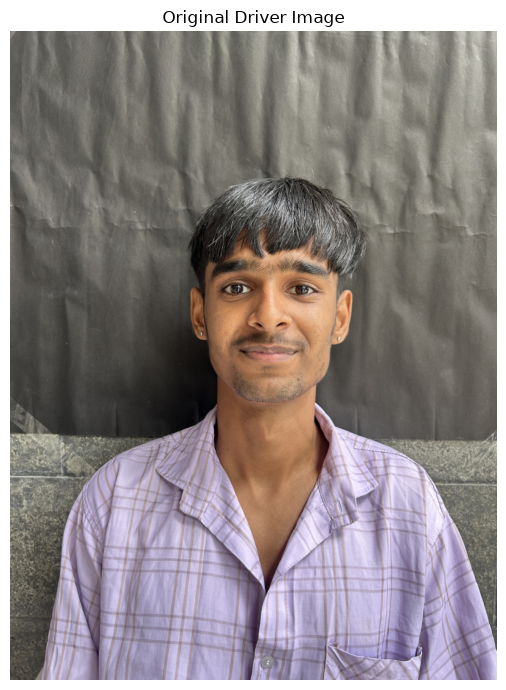

In [79]:

plt.figure(figsize=(10, 7))

plt.imshow(display_image_rgb)

plt.title("Original Driver Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [80]:
height, width, channels = image.shape

In [81]:
print("Image Information")
print("-" * 35)

Image Information
-----------------------------------


In [82]:
print(f"Width          : {width} pixels")
print(f"Height         : {height} pixels")
print(f"Channels       : {channels}")
print(f"Data type      : {image.dtype}")
print(f"Total pixels   : {width * height:,}")
print(f"Total values   : {image.size:,}")

Width          : 3024 pixels
Height         : 4032 pixels
Channels       : 3
Data type      : uint8
Total pixels   : 12,192,768
Total values   : 36,578,304


In [83]:
#saving original acquired img
acquisition_dir = PROCESSED_DIR / "image_acquisition"

In [84]:
acquisition_dir.mkdir(
    parents=True,
    exist_ok=True
)


In [85]:
output_path = acquisition_dir / "original_driver_image.jpg"

In [86]:
success = cv2.imwrite(
    str(output_path),
    image
)

In [91]:
if success:
    print("Original image saved successfully.")
    print(output_path)
else:
    print("Failed to save image.")

Original image saved successfully.
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\image_acquisition\original_driver_image.jpg


## 3.2 RGB Representation

The acquired image is initially loaded by OpenCV in BGR channel order.
For conventional image representation and visualization, the image is
converted from BGR to RGB format. The individual red, green, and blue
channels are also examined separately.

In [92]:
#BGR to RGB
rgb_image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

In [93]:
print("BGR to RGB conversion completed.")
print("Original image shape :", image.shape)
print("RGB image shape      :", rgb_image.shape)
print("RGB data type        :", rgb_image.dtype)

BGR to RGB conversion completed.
Original image shape : (4032, 3024, 3)
RGB image shape      : (4032, 3024, 3)
RGB data type        : uint8


In [94]:
#Display rgb img

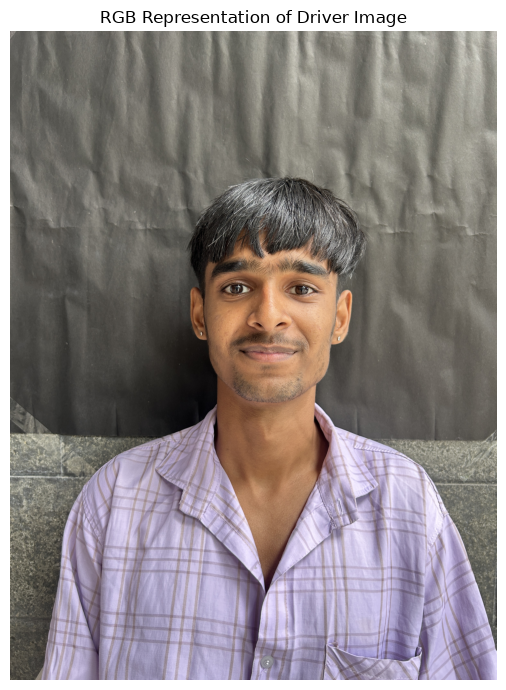

In [99]:
plt.figure(figsize=(10, 7))

plt.imshow(rgb_image)

plt.title("RGB Representation of Driver Image")

plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Extract RGB Channels

In [101]:
red_channel = rgb_image[:, :, 0]
green_channel = rgb_image[:, :, 1]
blue_channel = rgb_image[:, :, 2]


In [102]:
print("RGB channel extraction completed.")

print("Red channel shape  :", red_channel.shape)
print("Green channel shape:", green_channel.shape)
print("Blue channel shape :", blue_channel.shape)

RGB channel extraction completed.
Red channel shape  : (4032, 3024)
Green channel shape: (4032, 3024)
Blue channel shape : (4032, 3024)


In [103]:
# Display Individual RGB Channels

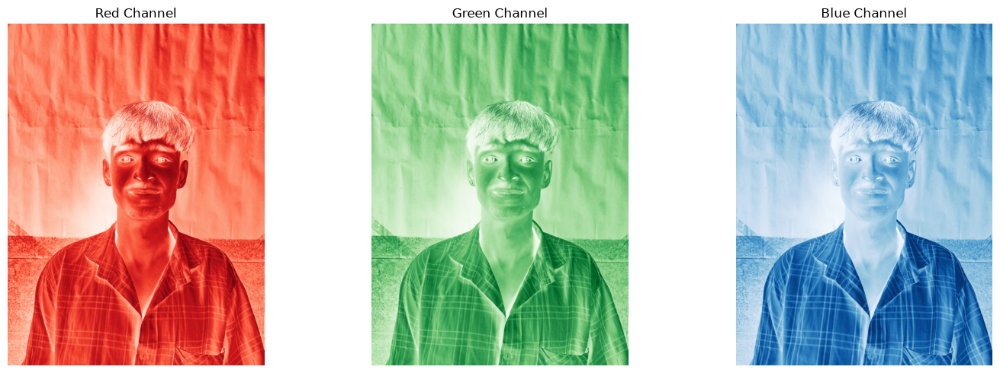

In [106]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(red_channel, cmap="Reds")
plt.title("Red Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(green_channel, cmap="Greens")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blue_channel, cmap="Blues")
plt.title("Blue Channel")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3.3 Grayscale Conversion

The RGB driver image is converted into a grayscale image to represent
intensity information using a single channel. Grayscale conversion reduces
the three-channel RGB representation to one intensity channel while
preserving the major structural information required for subsequent image
processing operations.

In [107]:
#RGB to Grayscale
gray_image = cv2.cvtColor(
    rgb_image,
    cv2.COLOR_RGB2GRAY
)

In [108]:
print("Grayscale conversion completed.")
print("Original RGB shape :", rgb_image.shape)
print("Grayscale shape    :", gray_image.shape)
print("Grayscale data type:", gray_image.dtype)

Grayscale conversion completed.
Original RGB shape : (4032, 3024, 3)
Grayscale shape    : (4032, 3024)
Grayscale data type: uint8


## 3.3 Grayscale Conversion

The RGB driver image is converted into a grayscale image to represent
intensity information using a single channel. Grayscale conversion reduces
the three-channel RGB representation to one intensity channel while
preserving the major structural information required for subsequent image
processing operations.

In [109]:
#RGB to Grayscale
gray_image = cv2.cvtColor(
    rgb_image,
    cv2.COLOR_RGB2GRAY
)


In [110]:
print("Grayscale conversion completed.")
print("Original RGB shape :", rgb_image.shape)
print("Grayscale shape    :", gray_image.shape)
print("Grayscale data type:", gray_image.dtype)

Grayscale conversion completed.
Original RGB shape : (4032, 3024, 3)
Grayscale shape    : (4032, 3024)
Grayscale data type: uint8


In [111]:
# Display Grayscale Image

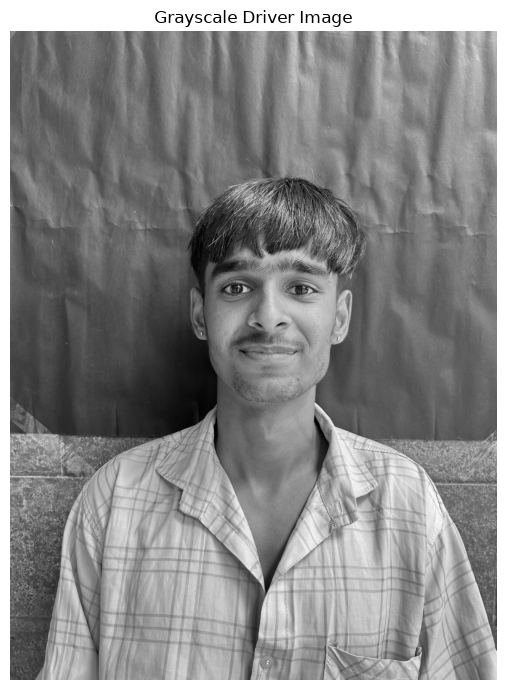

In [112]:
plt.figure(figsize=(10, 7))

plt.imshow(
    gray_image,
    cmap="gray"
)

plt.title("Grayscale Driver Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [115]:
# Grayscale Histogram

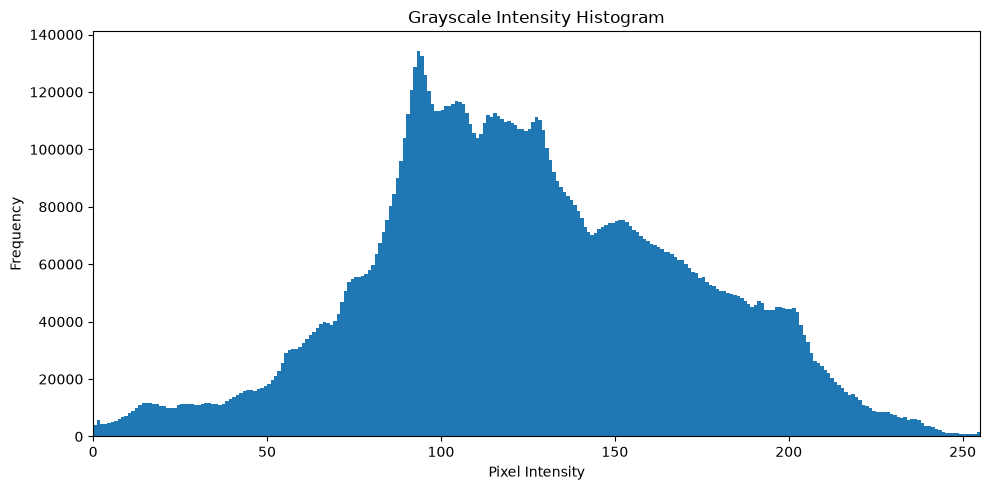

In [116]:
plt.figure(figsize=(10, 5))

plt.hist(
    gray_image.ravel(),
    bins=256,
    range=(0, 256)
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Grayscale Intensity Histogram")

plt.xlim(0, 255)
plt.tight_layout()
plt.show()

In [117]:


# Save Grayscale Image
gray_dir = PROCESSED_DIR / "color_space"

gray_dir.mkdir(
    parents=True,
    exist_ok=True
)

gray_output_path = gray_dir / "grayscale_driver_image.png"

cv2.imwrite(
    str(gray_output_path),
    gray_image
)

print("Grayscale image saved successfully:")
print(gray_output_path)

Grayscale image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\color_space\grayscale_driver_image.png


### Observation

The RGB driver image was converted into a single-channel grayscale image.
The resulting image preserves the major structural and intensity information
while reducing the number of image channels from three to one. The grayscale
representation is suitable for subsequent filtering, edge detection,
thresholding, morphological processing, and histogram-based enhancement.

In [119]:
#rgb to hsv

In [120]:
hsv_image = cv2.cvtColor(
    rgb_image,
    cv2.COLOR_RGB2HSV
)


In [121]:
print("RGB to HSV conversion completed.")
print("RGB image shape:", rgb_image.shape)
print("HSV image shape:", hsv_image.shape)
print("HSV data type:", hsv_image.dtype)

RGB to HSV conversion completed.
RGB image shape: (4032, 3024, 3)
HSV image shape: (4032, 3024, 3)
HSV data type: uint8


In [122]:
# Display HSV Components

In [123]:
hue = hsv_image[:, :, 0]
saturation = hsv_image[:, :, 1]
value = hsv_image[:, :, 2]


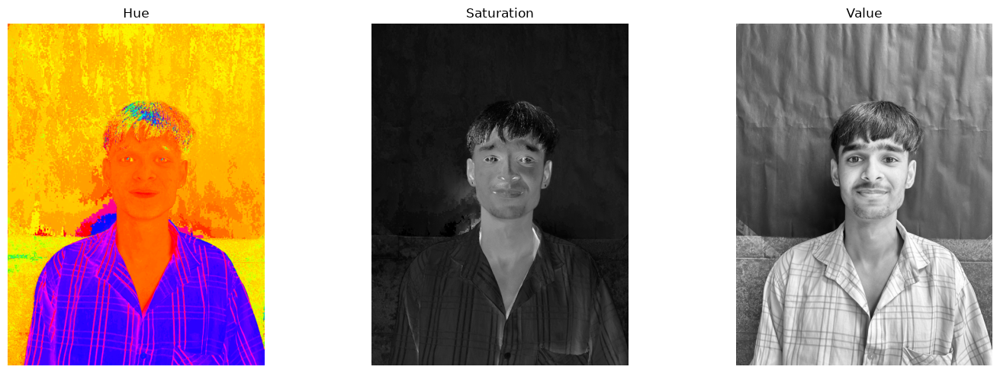

In [124]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(hue, cmap="hsv")
plt.title("Hue")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(saturation, cmap="gray")
plt.title("Saturation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(value, cmap="gray")
plt.title("Value")
plt.axis("off")

plt.tight_layout()
plt.show()

In [125]:
# HSV Channel Analysis

In [126]:
print("HSV Channel Ranges")
print("-" * 30)

print("Hue:")
print("Minimum:", hue.min())
print("Maximum:", hue.max())

print("\nSaturation:")
print("Minimum:", saturation.min())
print("Maximum:", saturation.max())

print("\nValue:")
print("Minimum:", value.min())
print("Maximum:", value.max())

HSV Channel Ranges
------------------------------
Hue:
Minimum: 0
Maximum: 179

Saturation:
Minimum: 0
Maximum: 255

Value:
Minimum: 0
Maximum: 255


In [127]:
# Save HSV 

In [128]:
hsv_dir = PROCESSED_DIR / "color_space"
hsv_dir.mkdir(parents=True, exist_ok=True)

In [129]:
cv2.imwrite(
    str(hsv_dir / "hue_channel.png"),
    hue
)

True

In [130]:
cv2.imwrite(
    str(hsv_dir / "saturation_channel.png"),
    saturation
)


True

In [131]:
cv2.imwrite(
    str(hsv_dir / "value_channel.png"),
    value
)

True

In [132]:
print("HSV components saved successfully.")
print(hsv_dir)

HSV components saved successfully.
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\color_space


### Observation

The RGB driver image was converted into the HSV color space while preserving
the original spatial dimensions and three-channel structure. The Hue,
Saturation, and Value components were extracted separately to examine color,
color intensity, and brightness information. The Value component provides
useful illumination information, while Hue and Saturation describe the color
properties of image regions.

## 3.5 Basic Image Operations

Basic image operations are applied to modify the spatial representation of
the acquired driver image. These operations include resizing, cropping,
rotation, horizontal flipping, vertical flipping, and pixel-level
manipulation.

### 3.5.1 Image Resizing

In [133]:
#img resizing

In [134]:
original_height, original_width = image.shape[:2]

In [135]:
print("Original image dimensions:")
print(f"Width  : {original_width} pixels")
print(f"Height : {original_height} pixels")


Original image dimensions:
Width  : 3024 pixels
Height : 4032 pixels


In [136]:
new_width = original_width // 2
new_height = original_height // 2

In [137]:
resized_image = cv2.resize(
    image,
    (new_width, new_height),
    interpolation=cv2.INTER_AREA
)

In [138]:
print("\nResized image dimensions:")
print(f"Width  : {new_width} pixels")
print(f"Height : {new_height} pixels")


Resized image dimensions:
Width  : 1512 pixels
Height : 2016 pixels


In [139]:
# Comparing Original and Resized Images

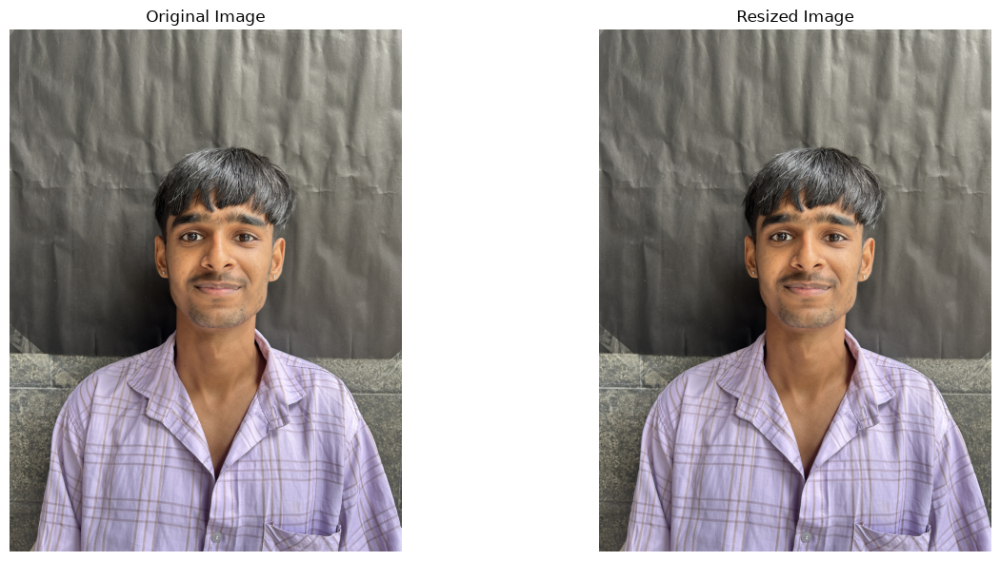

In [141]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title("Resized Image")
plt.axis("off")

plt.tight_layout()
plt.show()
new_width = original_width // 2
new_height = original_height // 2

### 3.5.2 Image Cropping

Image cropping is used to extract a specific region from an image by
selecting a range of rows and columns. Cropping reduces the image area
while preserving the original pixel information within the selected region.

In the Driver Monitoring System, cropping can be used to focus on relevant
regions such as the driver's face, head, or ear, reducing unnecessary
background information.

In [142]:
#img cropping
height, width = image.shape[:2]

In [143]:
print("Original image dimensions:")
print(f"Width  : {width} pixels")
print(f"Height : {height} pixels")


Original image dimensions:
Width  : 3024 pixels
Height : 4032 pixels


In [144]:
# Define crop coordinates
# y1:y2 -> vertical range
# x1:x2 -> horizontal range
x1 = int(width * 0.20)
x2 = int(width * 0.80)

y1 = int(height * 0.05)
y2 = int(height * 0.70)

In [145]:
# Cropping the image
cropped_image = image[y1:y2, x1:x2]

print("\nCropped image dimensions:")
print(f"Width  : {cropped_image.shape[1]} pixels")
print(f"Height : {cropped_image.shape[0]} pixels")


Cropped image dimensions:
Width  : 1815 pixels
Height : 2621 pixels


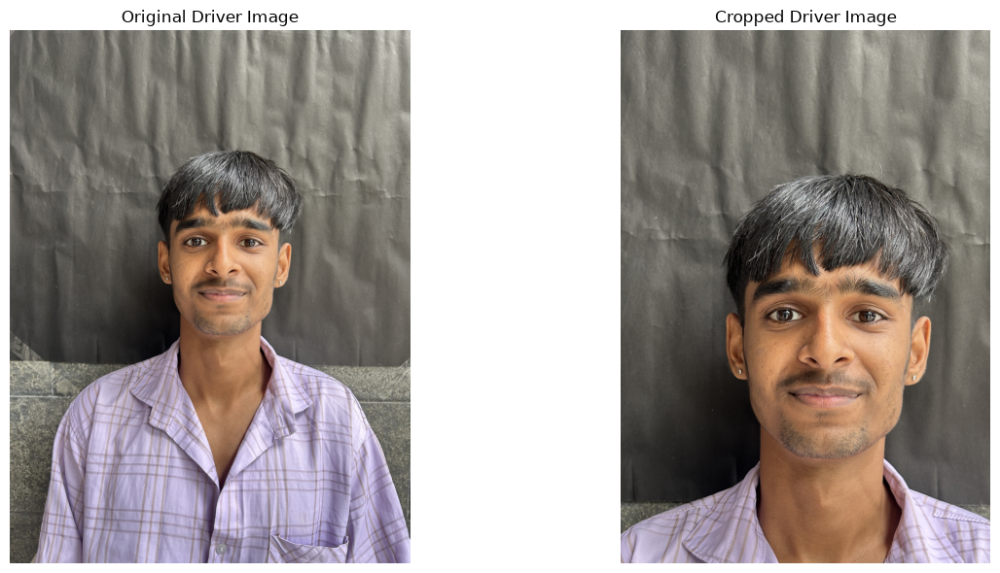

In [146]:
#display cropped and og img
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(cropped_image, cv2.COLOR_BGR2RGB))
plt.title("Cropped Driver Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [147]:
#saving cropped img
crop_dir = PROCESSED_DIR / "basic_operations"
crop_dir.mkdir(parents=True, exist_ok=True)

In [148]:
crop_path = crop_dir / "cropped_driver_image.jpg"

In [149]:
success = cv2.imwrite(
    str(crop_path),
    cropped_image
)

In [150]:
if success:
    print("Cropped image saved successfully:")
    print(crop_path)
else:
    print("Failed to save cropped image.")

Cropped image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\basic_operations\cropped_driver_image.jpg


### Observation

A selected region of the original driver image was extracted using image
cropping. The cropped image contains the relevant upper-central portion of
the driver while removing unnecessary regions of the original image.
Cropping can be used to focus subsequent image processing and detection
operations on important regions such as the driver's face and ear.

### 3.5.3 Image Rotation

Image rotation changes the orientation of an image around a specified center
point. In image preprocessing, rotation can be used to handle variations in
camera alignment and driver head or body orientation.

A positive angle rotates the image counterclockwise, while a negative angle
rotates it clockwise.

In [151]:
#img rotation
height, width = image.shape[:2]

In [152]:
# Define the center of rotation
center = (width // 2, height // 2)

In [153]:
# Rotation angle
angle = 10

In [154]:
# Rotation matrix
rotation_matrix = cv2.getRotationMatrix2D(
    center,
    angle,
    1.0
)

In [155]:
# Apply rotation
rotated_image = cv2.warpAffine(
    image,
    rotation_matrix,
    (width, height)
)

In [156]:
print("Image rotation completed.")
print("Rotation angle:", angle, "degrees")
print("Original shape:", image.shape)
print("Rotated shape :", rotated_image.shape)

Image rotation completed.
Rotation angle: 10 degrees
Original shape: (4032, 3024, 3)
Rotated shape : (4032, 3024, 3)


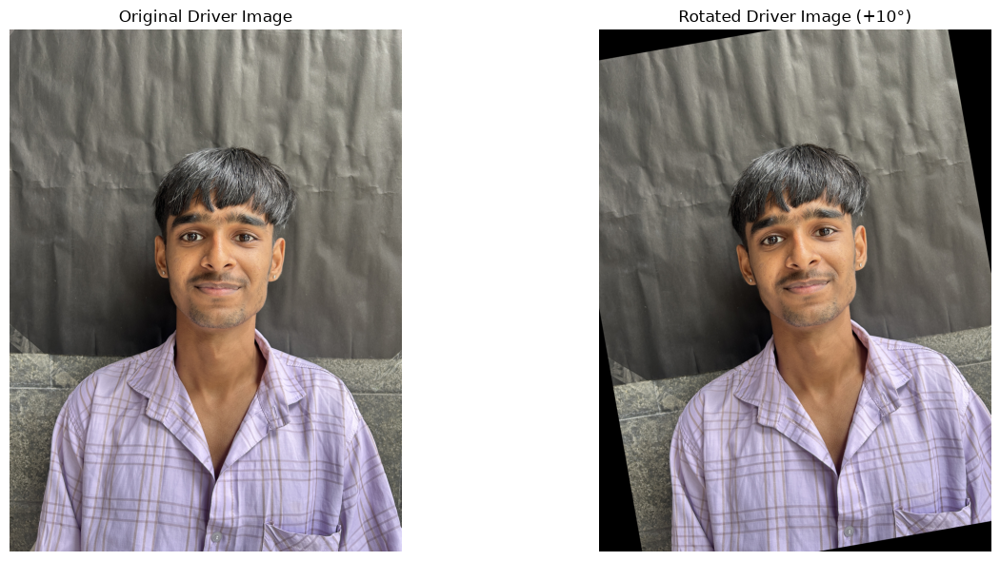

In [157]:
#display img
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB))
plt.title("Rotated Driver Image (+10°)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [158]:
#saving
rotation_dir = PROCESSED_DIR / "basic_operations"
rotation_dir.mkdir(parents=True, exist_ok=True)

In [159]:
rotation_path = rotation_dir / "rotated_driver_image_10deg.jpg"

In [160]:

success = cv2.imwrite(
    str(rotation_path),
    rotated_image
)


In [161]:
if success:
    print("Rotated image saved successfully:")
    print(rotation_path)
else:
    print("Failed to save rotated image.")

Rotated image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\basic_operations\rotated_driver_image_10deg.jpg


### Observation

The driver image was rotated by +10 degrees using an affine transformation.
The spatial dimensions of the image were maintained, while the orientation
of the driver was changed. Image rotation can help simulate variations in
camera alignment and driver orientation during image preprocessing.

### 3.5.4 Horizontal Flip

Horizontal flipping creates a mirror image by reversing the image along the
vertical axis. This operation changes the left-right orientation of the
driver image while preserving its height and width.

Horizontal flipping can be useful in image preprocessing and data
augmentation to increase variation in the training data.

In [162]:
#horizontal flip
# Apply horizontal flip
horizontal_flip = cv2.flip(
    image,
    1
)


In [163]:
print("Horizontal flip completed.")
print("Original shape :", image.shape)
print("Flipped shape  :", horizontal_flip.shape)

Horizontal flip completed.
Original shape : (4032, 3024, 3)
Flipped shape  : (4032, 3024, 3)


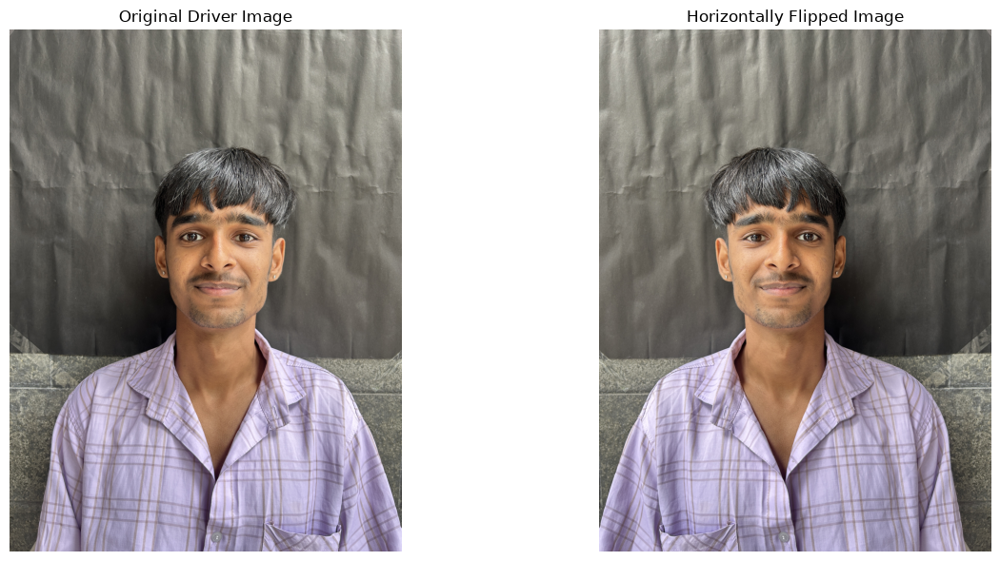

In [164]:
#display
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(horizontal_flip, cv2.COLOR_BGR2RGB))
plt.title("Horizontally Flipped Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [167]:
flip_dir = PROCESSED_DIR / "basic_operations"
flip_dir.mkdir(parents=True, exist_ok=True)


In [168]:
horizontal_flip_path = flip_dir / "horizontal_flip.jpg"

In [169]:
success = cv2.imwrite(
    str(horizontal_flip_path),
    horizontal_flip
)

In [170]:
if success:
    print("Horizontally flipped image saved successfully:")
    print(horizontal_flip_path)
else:
    print("Failed to save horizontally flipped image.")

Horizontally flipped image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\basic_operations\horizontal_flip.jpg


In [171]:
#vertical flip
vertical_flip = cv2.flip(
    image,
    0
)


In [172]:
print("Vertical flip completed.")
print("Original shape :", image.shape)
print("Flipped shape  :", vertical_flip.shape)

Vertical flip completed.
Original shape : (4032, 3024, 3)
Flipped shape  : (4032, 3024, 3)


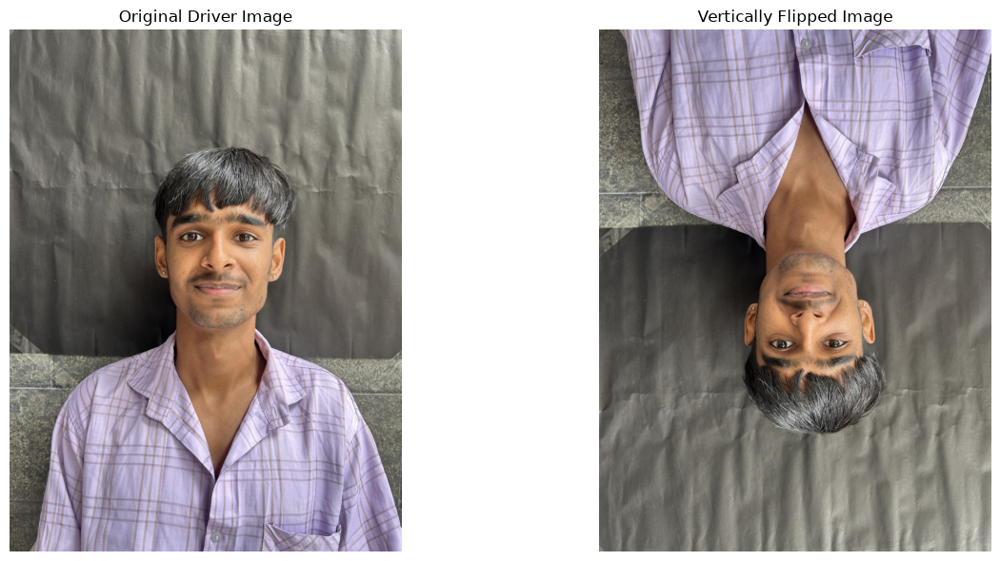

In [173]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(vertical_flip, cv2.COLOR_BGR2RGB))
plt.title("Vertically Flipped Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [174]:
#saving
flip_dir = PROCESSED_DIR / "basic_operations"
flip_dir.mkdir(parents=True, exist_ok=True)

In [175]:
vertical_flip_path = flip_dir / "vertical_flip.jpg"

In [176]:
success = cv2.imwrite(
    str(vertical_flip_path),
    vertical_flip
)


In [177]:
if success:
    print("Vertically flipped image saved successfully:")
    print(vertical_flip_path)
else:
    print("Failed to save vertically flipped image.")

Vertically flipped image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\basic_operations\vertical_flip.jpg


### 3.5.6 Pixel Manipulation

Pixel manipulation involves accessing and modifying individual pixel values
within an image. Each pixel in a color image contains separate intensity
values for its color channels.

In this experiment, individual pixel values are accessed and modified to
demonstrate how image data can be manipulated at the pixel level.

In [178]:
# Select the center pixel
y = image.shape[0] // 2
x = image.shape[1] // 2


In [179]:
pixel_value = image[y, x]


In [180]:
print("Selected pixel position:")
print(f"x = {x}, y = {y}")

print("\nBGR pixel value:")
print(f"Blue  : {pixel_value[0]}")
print(f"Green : {pixel_value[1]}")
print(f"Red   : {pixel_value[2]}")

Selected pixel position:
x = 1512, y = 2016

BGR pixel value:
Blue  : 88
Green : 105
Red   : 162


In [182]:
# Create a copy of the original image
pixel_modified_image = image.copy()


In [183]:
# Modify the center pixel
pixel_modified_image[y, x] = [0, 0, 255]

In [184]:
print("Center pixel modified successfully.")
print("New BGR value:", pixel_modified_image[y, x])

Center pixel modified successfully.
New BGR value: [  0   0 255]


In [185]:
pixel_region_image = image.copy()

In [186]:
# Define a 20 × 20 region around the center
region_size = 20

In [187]:

y1 = y - region_size // 2
y2 = y + region_size // 2
x1 = x - region_size // 2
x2 = x + region_size // 2

In [188]:
# Set the region to red
pixel_region_image[y1:y2, x1:x2] = [0, 0, 255]

In [189]:
print("20 × 20 pixel region modified.")
print(f"Region coordinates: x={x1}:{x2}, y={y1}:{y2}")

20 × 20 pixel region modified.
Region coordinates: x=1502:1522, y=2006:2026


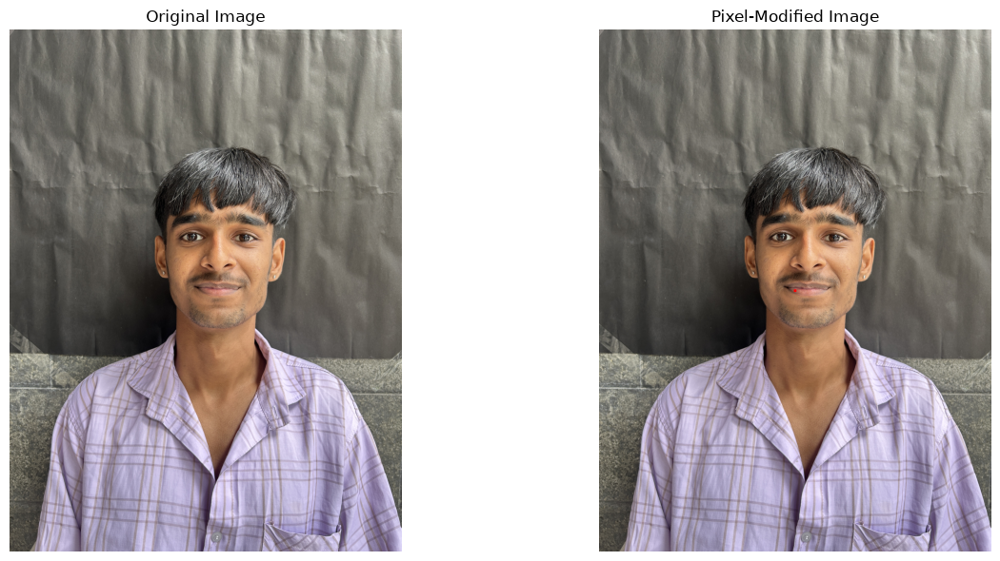

In [190]:
#display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(pixel_region_image, cv2.COLOR_BGR2RGB))
plt.title("Pixel-Modified Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [191]:
pixel_dir = PROCESSED_DIR / "basic_operations"
pixel_dir.mkdir(parents=True, exist_ok=True)


In [192]:
pixel_path = pixel_dir / "pixel_manipulated_image.jpg"

In [193]:
success = cv2.imwrite(
    str(pixel_path),
    pixel_region_image
)

In [194]:
if success:
    print("Pixel-manipulated image saved successfully:")
    print(pixel_path)
else:
    print("Failed to save pixel-manipulated image.")

Pixel-manipulated image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\basic_operations\pixel_manipulated_image.jpg


### Observation

Individual pixel values were accessed and modified using NumPy array
indexing. A small region of the driver image was changed by assigning new
BGR intensity values to its pixels. This demonstrates that digital images
can be manipulated directly at the pixel level and that each pixel contains
numerical color information.

## 4. IMAGE FILTERING

Image filtering is used to modify image information by applying mathematical
operations to pixels and their neighboring pixels. Filtering can be used for
noise reduction, image smoothing, and preparation of images for subsequent
processing operations.

### 4.1 Mean / Average Filtering

Mean filtering replaces each pixel with the average value of the pixels
within a specified neighborhood. It reduces small variations and noise in
the image while producing a smoothing effect.

In [196]:
# Apply mean filtering using a 5 × 5 kernel
mean_filtered_image = cv2.blur(
    image,
    (5, 5)
)


In [197]:
print("Mean filtering completed.")
print("Original image shape :", image.shape)
print("Filtered image shape :", mean_filtered_image.shape)

Mean filtering completed.
Original image shape : (4032, 3024, 3)
Filtered image shape : (4032, 3024, 3)


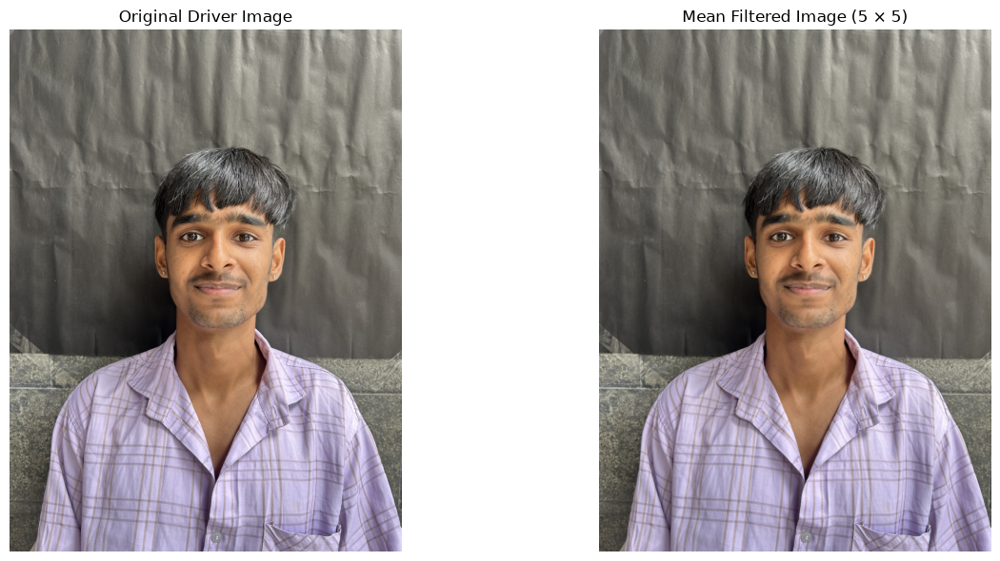

In [198]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(mean_filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Mean Filtered Image (5 × 5)")
plt.axis("off")

plt.tight_layout()
plt.show()

### 4.2 Gaussian Filtering

Gaussian filtering is a smoothing technique that uses a Gaussian kernel to
calculate a weighted average of neighboring pixels. Pixels closer to the
center of the kernel receive higher weights than pixels farther away.

Gaussian filtering is commonly used for noise reduction and image smoothing
while preserving important image structures better than simple mean
filtering.

In [199]:
# Apply Gaussian filtering using a 5 × 5 kernel
gaussian_filtered_image = cv2.GaussianBlur(
    image,
    (5, 5),
    0
)

In [200]:
print("Gaussian filtering completed.")
print("Original image shape :", image.shape)
print("Filtered image shape :", gaussian_filtered_image.shape)

Gaussian filtering completed.
Original image shape : (4032, 3024, 3)
Filtered image shape : (4032, 3024, 3)


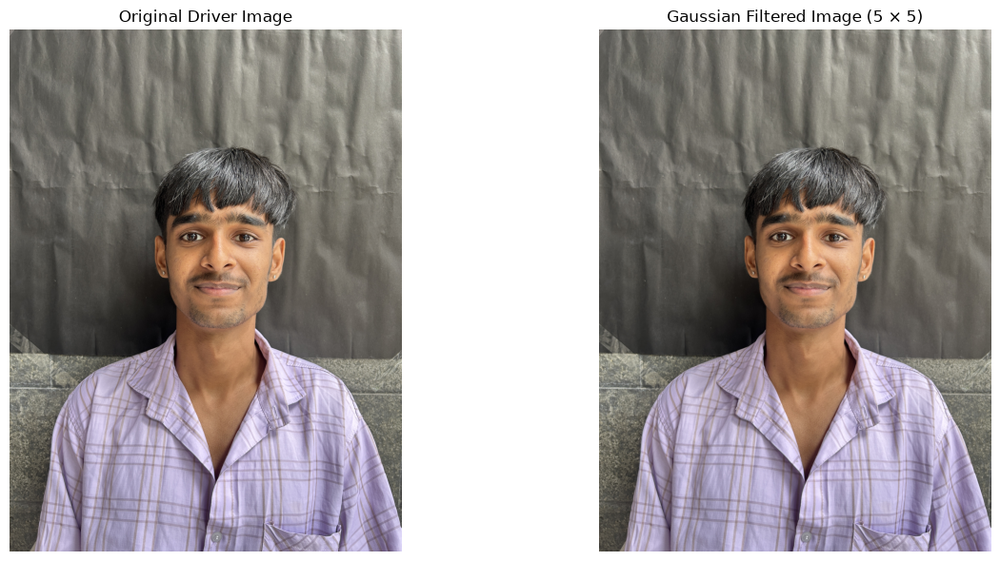

In [201]:
#display
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(gaussian_filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filtered Image (5 × 5)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [205]:
# Create folder for filtered images
filter_dir = PROCESSED_DIR / "filtering"
filter_dir.mkdir(parents=True, exist_ok=True)

In [206]:

print("Filter directory:")
print(filter_dir)

Filter directory:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\filtering


In [207]:
# Save Gaussian filtered image
gaussian_filter_path = filter_dir / "gaussian_filtered_image.jpg"


In [208]:

success = cv2.imwrite(
    str(gaussian_filter_path),
    gaussian_filtered_image
)


In [209]:
if success:
    print("Gaussian filtered image saved successfully:")
    print(gaussian_filter_path)
else:
    print("Failed to save Gaussian filtered image.")

Gaussian filtered image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\filtering\gaussian_filtered_image.jpg


### 4.3 Median Filtering

Median filtering is a nonlinear image filtering technique used to reduce
noise while preserving important edges. For each pixel, the values within
a specified neighborhood are arranged in order, and the median value is
used to replace the center pixel.

Median filtering is particularly effective for removing salt-and-pepper
noise from images.

In [210]:
# Apply median filtering using a 5 × 5 kernel
median_filtered_image = cv2.medianBlur(
    image,
    5
)

In [211]:
print("Median filtering completed.")
print("Original image shape :", image.shape)
print("Filtered image shape :", median_filtered_image.shape)

Median filtering completed.
Original image shape : (4032, 3024, 3)
Filtered image shape : (4032, 3024, 3)


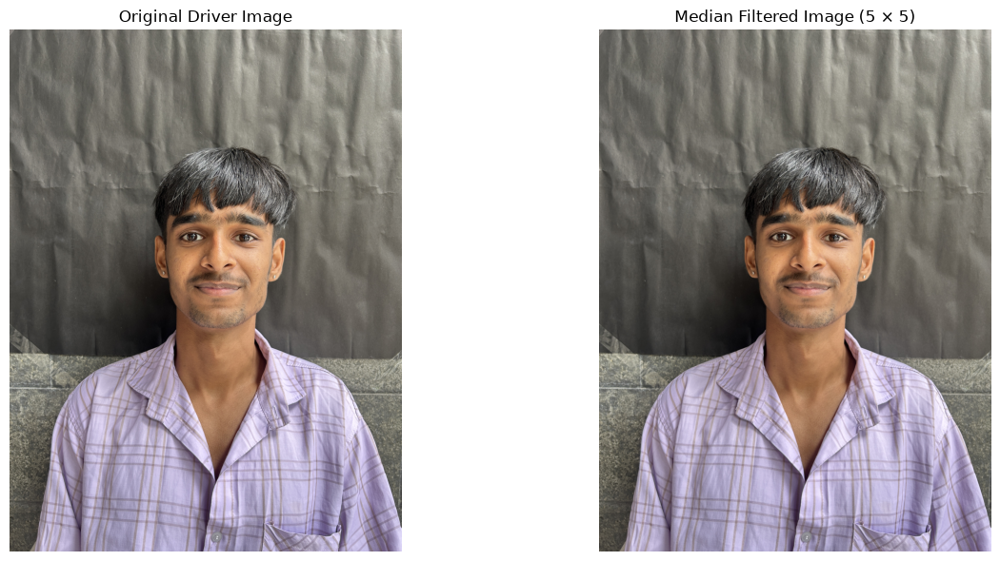

In [212]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(median_filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Median Filtered Image (5 × 5)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [213]:
filter_dir = PROCESSED_DIR / "filtering"
filter_dir.mkdir(parents=True, exist_ok=True)

In [214]:
median_filter_path = filter_dir / "median_filtered_image.jpg"

In [215]:
success = cv2.imwrite(
    str(median_filter_path),
    median_filtered_image
)

In [216]:
if success:
    print("Median filtered image saved successfully:")
    print(median_filter_path)
else:
    print("Failed to save median filtered image.")

Median filtered image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\filtering\median_filtered_image.jpg


### 4.4 Bilateral Filtering

Bilateral filtering is an edge-preserving smoothing technique that reduces
noise while maintaining important boundaries in an image. Unlike simple
averaging filters, bilateral filtering considers both the spatial distance
between pixels and the difference in their intensity or color values.

This makes bilateral filtering useful for smoothing driver images while
preserving important structures such as facial and ear boundaries.

In [217]:
# Apply bilateral filtering
bilateral_filtered_image = cv2.bilateralFilter(
    image,
    9,
    75,
    75
)

In [218]:
print("Bilateral filtering completed.")
print("Original image shape :", image.shape)
print("Filtered image shape :", bilateral_filtered_image.shape)

Bilateral filtering completed.
Original image shape : (4032, 3024, 3)
Filtered image shape : (4032, 3024, 3)


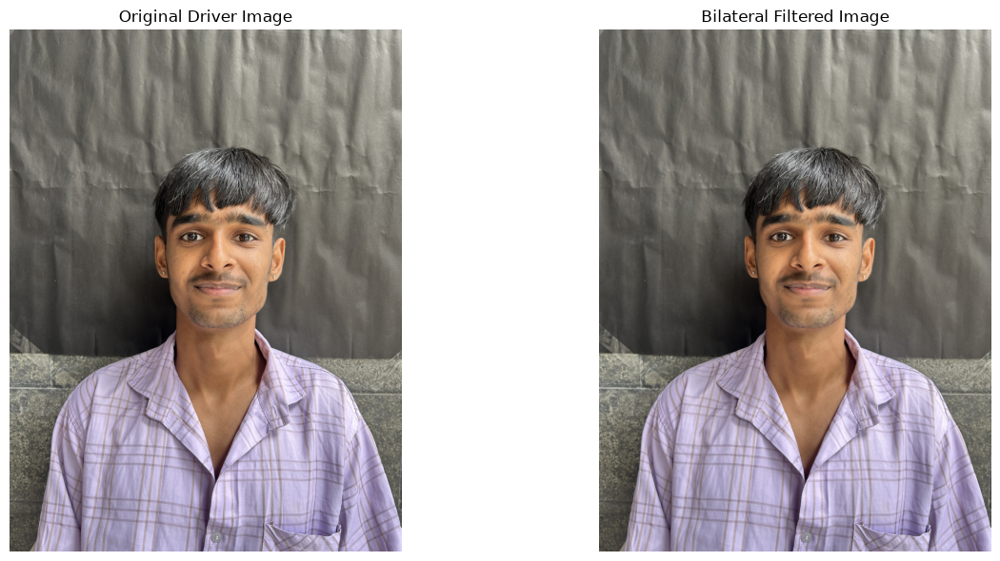

In [219]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(bilateral_filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Bilateral Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [220]:
filter_dir = PROCESSED_DIR / "filtering"
filter_dir.mkdir(parents=True, exist_ok=True)


In [221]:
bilateral_filter_path = filter_dir / "bilateral_filtered_image.jpg"

In [222]:
success = cv2.imwrite(
    str(bilateral_filter_path),
    bilateral_filtered_image
)

In [223]:
if success:
    print("Bilateral filtered image saved successfully:")
    print(bilateral_filter_path)
else:
    print("Failed to save bilateral filtered image.")

Bilateral filtered image saved successfully:
C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\filtering\bilateral_filtered_image.jpg


In [1]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\Admin\Desktop\DriverMonitoringSystem\.venv\Scripts\python.exe

Python version:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


# 5. UNIT 3 - EDGE DETECTION

Edge detection identifies boundaries in an image by detecting rapid
changes in pixel intensity. These boundaries can represent object
outlines, facial features, and other structural details.

Edge detection is useful in image analysis because it highlights
important structures that may be used in later image processing
and object detection stages.

## 5.1 Sobel Edge Detection

The Sobel operator estimates image intensity gradients in the
horizontal and vertical directions. These gradients are combined
to identify regions with strong intensity changes.

In [3]:
# Import required libraries
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from collections import Counter

print("Libraries imported successfully.")
print("OpenCV version:", cv2.__version__)

Libraries imported successfully.
OpenCV version: 5.0.0


In [4]:
print("Image variable exists:", "image" in globals())

Image variable exists: False


In [5]:
# Define the project path
PROJECT_ROOT = Path.cwd()


In [6]:
# Locate the front-view image folder
front_dir = PROJECT_ROOT / "Images" / "front"

In [7]:
# Find supported image files
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

In [8]:
front_images = sorted([
    p for p in front_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
])


In [9]:
# Load the first front-view image
IMAGE_PATH = front_images[0]
image = cv2.imread(str(IMAGE_PATH))

In [10]:
if image is None:
    raise FileNotFoundError(f"Could not load image: {IMAGE_PATH}")

print("Image loaded successfully.")
print("Image path:", IMAGE_PATH)
print("Image shape:", image.shape)

Image loaded successfully.
Image path: C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4159.JPG
Image shape: (4032, 3024, 3)


In [11]:
# Convert the original image to grayscale
sobel_gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)

In [12]:
print("Grayscale conversion completed.")
print("Image shape:", sobel_gray.shape)

Grayscale conversion completed.
Image shape: (4032, 3024)


In [13]:
#horizontal intensity gradient
sobel_x = cv2.Sobel(
    sobel_gray,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

In [14]:
print("Sobel X gradient calculated successfully.")
print("Sobel X shape:", sobel_x.shape)
print("Minimum gradient value:", sobel_x.min())
print("Maximum gradient value:", sobel_x.max())

Sobel X gradient calculated successfully.
Sobel X shape: (4032, 3024)
Minimum gradient value: -1016.0
Maximum gradient value: 1016.0


In [15]:
plt.figure(figsize=(10, 6))


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

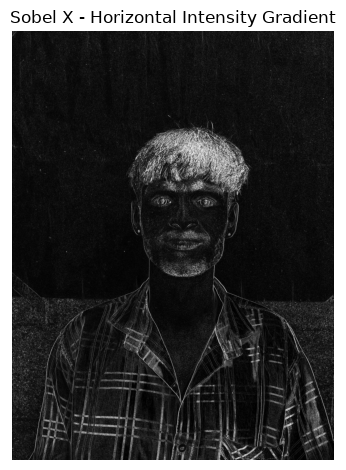

In [16]:
plt.imshow(
    cv2.convertScaleAbs(sobel_x),
    cmap="gray"
)

plt.title("Sobel X - Horizontal Intensity Gradient")
plt.axis("off")
plt.tight_layout()
plt.show()

In [17]:
#vertical intensity gradient

In [18]:
sobel_y = cv2.Sobel(
    sobel_gray,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)

In [19]:
print("Sobel Y gradient calculated successfully.")
print("Sobel Y shape:", sobel_y.shape)
print("Minimum gradient value:", sobel_y.min())
print("Maximum gradient value:", sobel_y.max())

Sobel Y gradient calculated successfully.
Sobel Y shape: (4032, 3024)
Minimum gradient value: -1009.0
Maximum gradient value: 999.0


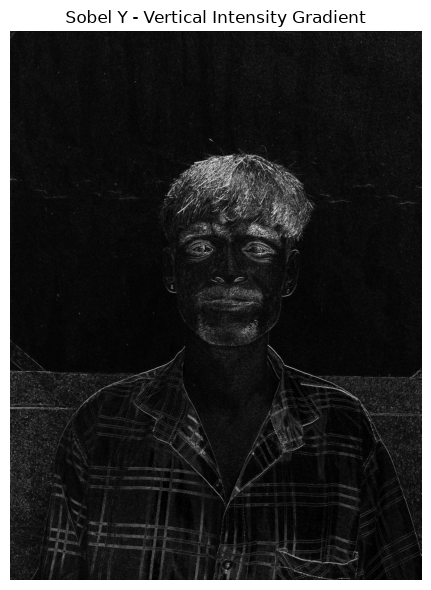

In [20]:
plt.figure(figsize=(10, 6))

plt.imshow(
    cv2.convertScaleAbs(sobel_y),
    cmap="gray"
)

plt.title("Sobel Y - Vertical Intensity Gradient")
plt.axis("off")
plt.tight_layout()
plt.show()


In [21]:
#final sobel
sobel_magnitude = cv2.magnitude(
    sobel_x,
    sobel_y
)

In [22]:
# Convert gradient magnitude to an 8-bit image
sobel_edges = cv2.convertScaleAbs(
    sobel_magnitude
)


In [23]:
print("Combined Sobel edge detection completed.")
print("Sobel magnitude shape:", sobel_magnitude.shape)
print("Final edge image shape:", sobel_edges.shape)

Combined Sobel edge detection completed.
Sobel magnitude shape: (4032, 3024)
Final edge image shape: (4032, 3024)


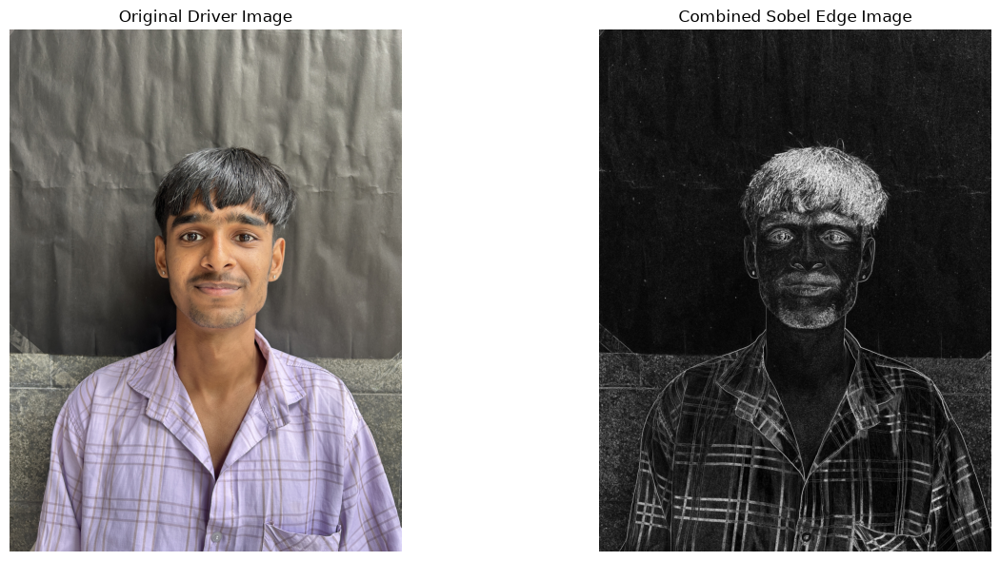

In [24]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sobel_edges, cmap="gray")
plt.title("Combined Sobel Edge Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation: Combined Sobel Edge Detection

The Sobel X and Sobel Y gradients were combined to calculate the overall
intensity gradient magnitude. The resulting edge image highlights regions
with strong intensity changes in both directions. Structural boundaries
such as facial outlines, hair, clothing, and background patterns may be
visible. However, the Sobel operator detects intensity transitions rather
than identifying specific objects.

The gradient magnitude is calculated as:
\[
G = \sqrt{G_x^2 + G_y^2}
\]

- \(G_x\): horizontal-direction derivative.
- \(G_y\): vertical-direction derivative.
- \(G\): combined gradient magnitude.

## 5.2 Laplacian Edge Detection

The Laplacian operator is an edge detection technique that uses second-order
derivatives to identify rapid changes in image intensity. It considers
intensity variations in both horizontal and vertical directions.

Laplacian edge detection can highlight boundaries and fine structural details
in the driver image. However, it can also respond strongly to image noise.

In [28]:
# Convert the original image to grayscale
laplacian_gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)


In [29]:
# Apply the Laplacian operator
laplacian = cv2.Laplacian(
    laplacian_gray,
    cv2.CV_64F,
    ksize=3
)

In [30]:
# Convert the result to an 8-bit image for display
laplacian_edges = cv2.convertScaleAbs(
    laplacian
)

In [31]:
print("Laplacian edge detection completed.")
print("Grayscale shape :", laplacian_gray.shape)
print("Laplacian shape :", laplacian.shape)
print("Edge image shape:", laplacian_edges.shape)

Laplacian edge detection completed.
Grayscale shape : (4032, 3024)
Laplacian shape : (4032, 3024)
Edge image shape: (4032, 3024)


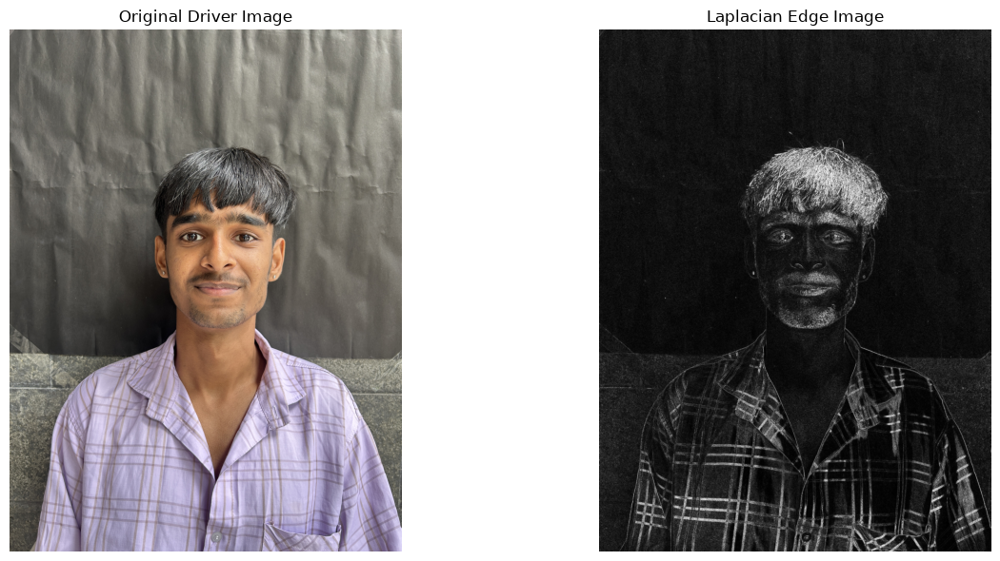

In [32]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
)
plt.title("Original Driver Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    laplacian_edges,
    cmap="gray"
)
plt.title("Laplacian Edge Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation: Laplacian Edge Detection

The Laplacian operator was applied to the grayscale driver image using a
3 × 3 kernel. The resulting image highlights regions with rapid intensity
changes, including facial boundaries, hair, clothing edges, and background
textures. The operator can also amplify noise, making it useful to compare
its output with other edge detection techniques.

In [34]:
#canny edge detection
# Convert the original image to grayscale
canny_gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY
)

In [35]:
# Reduce noise before detecting edges
canny_blurred = cv2.GaussianBlur(
    canny_gray,
    (5, 5),
    0
)

In [36]:
# Apply Canny edge detection
canny_edges = cv2.Canny(
    canny_blurred,
    50,
    150
)

In [37]:
print("Canny edge detection completed.")
print("Grayscale shape :", canny_gray.shape)
print("Blurred shape   :", canny_blurred.shape)
print("Edge image shape:", canny_edges.shape)

Canny edge detection completed.
Grayscale shape : (4032, 3024)
Blurred shape   : (4032, 3024)
Edge image shape: (4032, 3024)


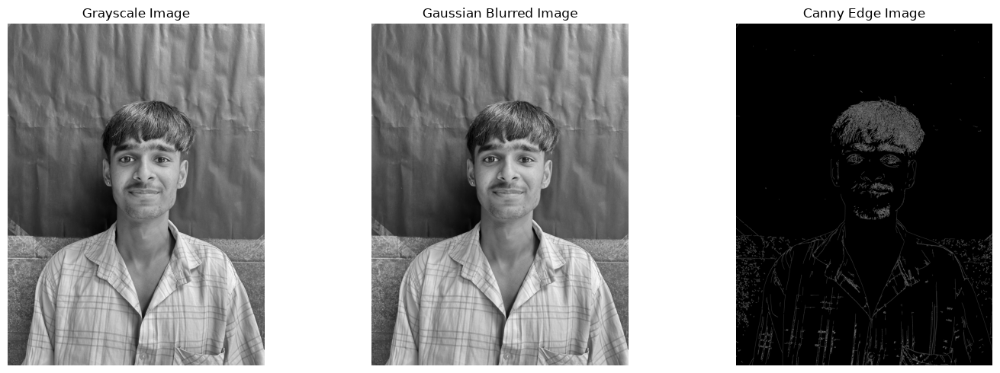

In [38]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(canny_gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(canny_blurred, cmap="gray")
plt.title("Gaussian Blurred Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edge Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation: Canny Edge Detection

Canny edge detection was applied to the grayscale driver image after
Gaussian smoothing. The algorithm produced an edge map containing thin
boundaries corresponding to intensity transitions in the image.
The result highlights structural details such as facial outlines,
hair, clothing, and background boundaries. The detected edges depend
on the selected threshold values and image quality.

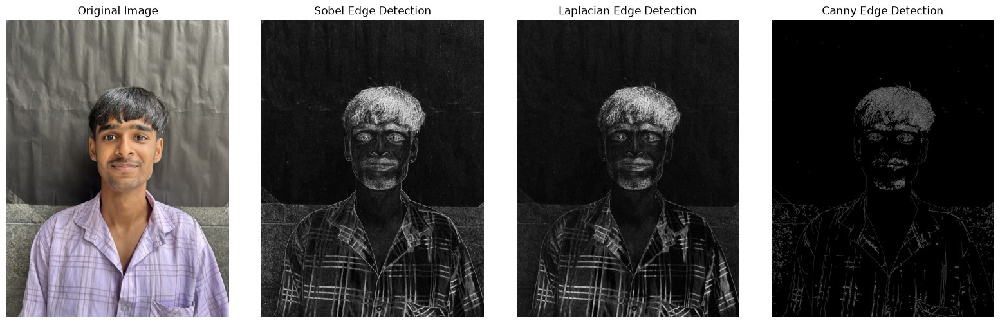

Comparison saved successfully.
Location: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\edge_detection\edge_detection_comparison.png


In [39]:
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# Define the output directory
edge_dir = Path.cwd() / "processed_images" / "edge_detection"
edge_dir.mkdir(parents=True, exist_ok=True)

# Convert the original image from BGR to RGB for display
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display all methods side by side
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(sobel_edges, cmap="gray")
plt.title("Sobel Edge Detection")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(laplacian_edges, cmap="gray")
plt.title("Laplacian Edge Detection")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()

# Save the comparison figure
plt.savefig(
    edge_dir / "edge_detection_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Comparison saved successfully.")
print("Location:", edge_dir / "edge_detection_comparison.png")

Method	Main characteristic
Sobel :	   Detects intensity changes along horizontal and vertical directions.

Laplacian :	Detects rapid intensity changes in multiple directions, but can be sensitive              to noise.

Canny	:  Uses smoothing, gradient detection, and edge refinement to produce clearer,                thinner edges in many cases.

## 6.1 Simple Binary Thresholding

Thresholding classifies pixels based on their intensity values.
Pixels above the threshold are assigned one value, and pixels
below or equal to the threshold are assigned another value.

In [40]:
# Convert the original BGR image to grayscale
threshold_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [41]:
# Set the threshold value
threshold_value = 127


In [42]:
# Apply binary thresholding
_, binary_image = cv2.threshold(
    threshold_gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)


In [43]:
# Display grayscale and binary images
plt.figure(figsize=(12, 5))


<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

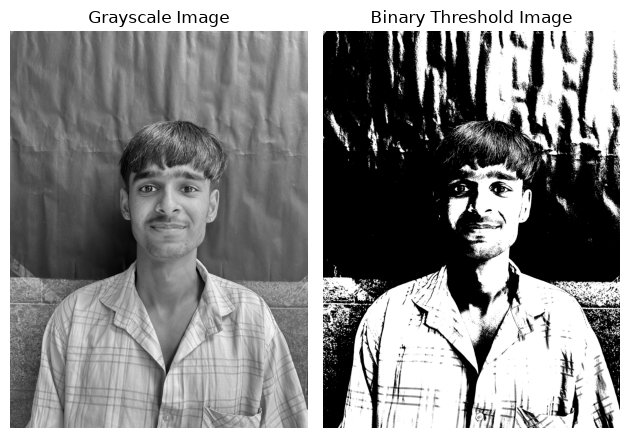

In [44]:
plt.subplot(1, 2, 1)
plt.imshow(threshold_gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Threshold Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In cv2.threshold(), the arguments are:
Parameter	          Meaning
threshold_gray	      Input grayscale image
127	                  Threshold intensity
255	                   Value assigned to pixels above the threshold
cv2.THRESH_BINARY	   Binary thresholding method

The rule is:

             B(x,y) = 255,   I(x,y)>127
             
                       0,    I(x,y)<=127
           


In [45]:
import numpy as np

unique_values = np.unique(binary_image)

print("Unique pixel values:", unique_values)
print("Image shape:", binary_image.shape)
print("Data type:", binary_image.dtype)

Unique pixel values: [  0 255]
Image shape: (4032, 3024)
Data type: uint8


A single threshold value can struggle when one part of an image is bright and another is dark. Adaptive thresholding calculates a threshold for each local neighborhood, which can help with uneven illumination.

In [46]:
#adaptive threshold
# Ensure the input is grayscale
adaptive_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [47]:
# Reduce noise before thresholding
adaptive_blurred = cv2.GaussianBlur(
    adaptive_gray,
    (5, 5),
    0
)

In [48]:
# Adaptive mean thresholding
adaptive_mean = cv2.adaptiveThreshold(
    adaptive_blurred,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

In [49]:
# Adaptive Gaussian thresholding
adaptive_gaussian = cv2.adaptiveThreshold(
    adaptive_blurred,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

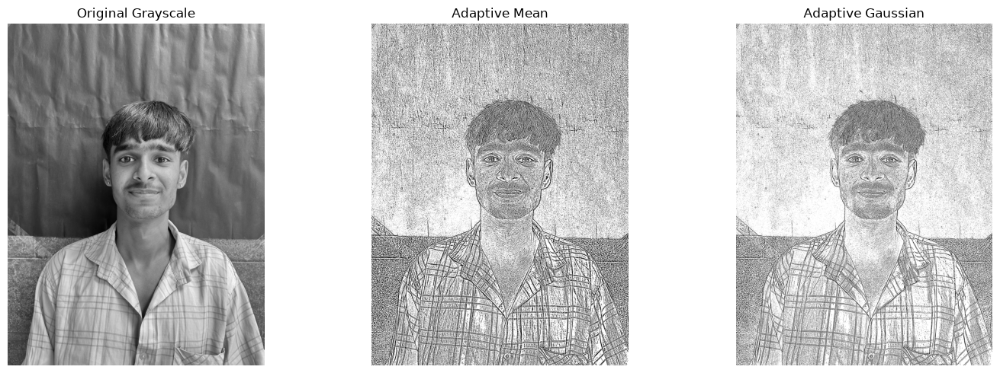

In [50]:
# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(adaptive_gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(adaptive_mean, cmap="gray")
plt.title("Adaptive Mean")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_gaussian, cmap="gray")
plt.title("Adaptive Gaussian")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Global thresholding uses one intensity threshold for the entire image.
Adaptive thresholding calculates local thresholds, which can be useful
under uneven lighting.

Adaptive thresholding may also produce unwanted noise or fragmented
regions. Its effectiveness depends on image quality and parameter settings.

## 6.4 Otsu's Thresholding

Otsu's thresholding automatically determines a threshold value
by separating grayscale pixels into two intensity classes.

It selects a threshold that minimizes the within-class variance
between the foreground and background pixel groups.

Otsu's method is useful when the image has a reasonably separable
foreground and background intensity distribution.

In [51]:
import cv2
import matplotlib.pyplot as plt

In [52]:
# Convert the original image to grayscale
otsu_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [53]:
# Apply Otsu's thresholding
otsu_threshold, otsu_binary = cv2.threshold(
    otsu_gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

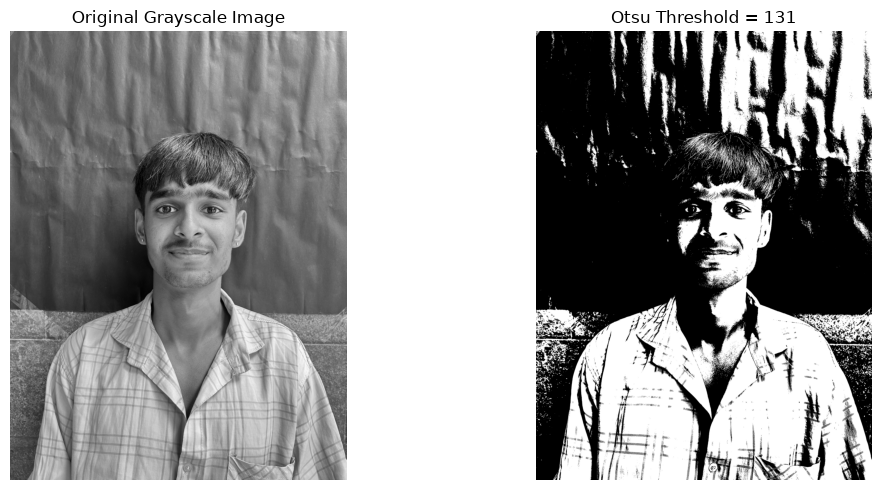

Automatically selected threshold: 131.0


In [54]:
# Display the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(otsu_gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu_binary, cmap="gray")
plt.title(f"Otsu Threshold = {otsu_threshold:.0f}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Automatically selected threshold:", otsu_threshold)

In [55]:
# Apply a fixed threshold for comparison
_, fixed_binary = cv2.threshold(
    otsu_gray,
    127,
    255,
    cv2.THRESH_BINARY
)

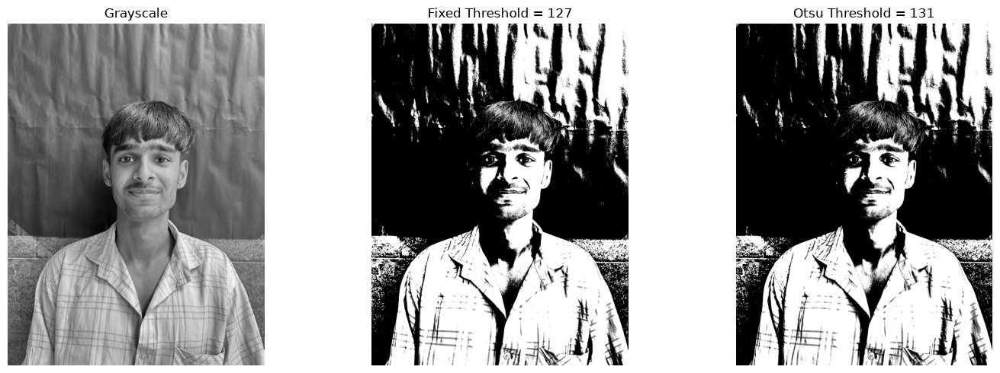

In [56]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(otsu_gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(fixed_binary, cmap="gray")
plt.title("Fixed Threshold = 127")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_binary, cmap="gray")
plt.title(f"Otsu Threshold = {otsu_threshold:.0f}")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Otsu's method automatically selects a global threshold based on
the image's grayscale intensity distribution.

The fixed threshold uses a manually chosen value, whereas Otsu's
method determines a threshold from the image itself.

Otsu's method does not guarantee perfect foreground-background
separation, especially when lighting is uneven or the intensity
distributions overlap.

## 6.5 Morphological Operations: Erosion

Erosion is a morphological operation that reduces the size of
white foreground regions in a binary image.

It uses a structuring element, also called a kernel, to determine
which pixels remain white.

Erosion can help remove small white regions and separate objects
that are connected by narrow white areas.

In [57]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Convert the original image to grayscale
erosion_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [58]:
# Convert grayscale image into a binary image
_, erosion_binary = cv2.threshold(
    erosion_gray,
    127,
    255,
    cv2.THRESH_BINARY
)


In [59]:
# Create a 3x3 structuring element
kernel = np.ones((3, 3), np.uint8)

In [60]:
# Apply erosion
eroded_image = cv2.erode(
    erosion_binary,
    kernel,
    iterations=1
)

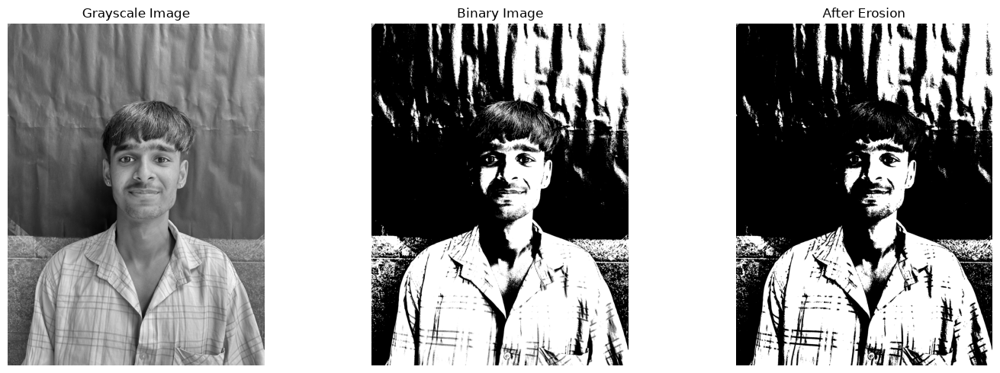

In [62]:
# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(erosion_gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(erosion_binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(eroded_image, cmap="gray")
plt.title("After Erosion")
plt.axis("off")

plt.tight_layout()
plt.show()


In [63]:
from pathlib import Path

morphology_dir = Path.cwd() / "processed_images" / "morphological_operations"
morphology_dir.mkdir(parents=True, exist_ok=True)

save_path = morphology_dir / "eroded_image.jpg"

success = cv2.imwrite(str(save_path), eroded_image)

if success:
    print("Eroded image saved successfully:", save_path)
else:
    print("Error: Could not save the image.")

Eroded image saved successfully: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\morphological_operations\eroded_image.jpg


`Dilation

Dilation is a morphological operation that expands white foreground
regions in a binary image.

It uses a structuring element called a kernel to determine which
pixels are added around existing white regions.

Dilation can help fill small gaps and connect nearby foreground regions.

In [64]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [65]:
# Convert the original image to grayscale
dilation_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [66]:
# Convert grayscale image to binary
_, dilation_binary = cv2.threshold(
    dilation_gray,
    127,
    255,
    cv2.THRESH_BINARY
)

In [67]:
# Create a 3x3 kernel
kernel = np.ones((3, 3), np.uint8)

In [68]:
# Apply dilation
dilated_image = cv2.dilate(
    dilation_binary,
    kernel,
    iterations=1
)

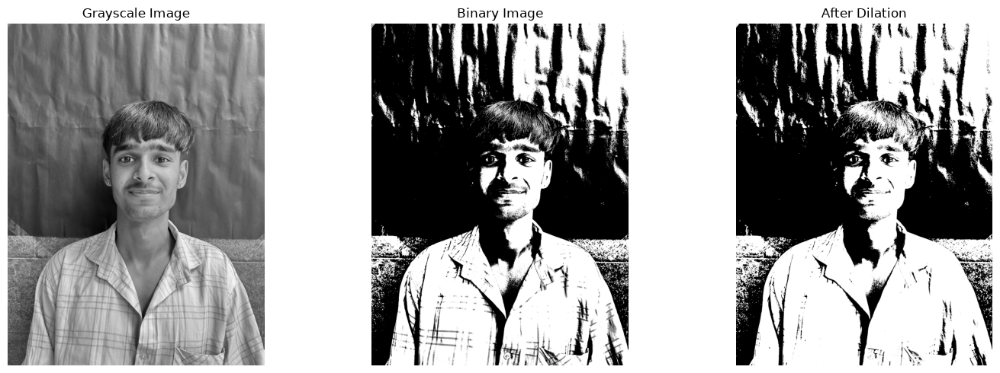

In [69]:
# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(dilation_gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(dilation_binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dilated_image, cmap="gray")
plt.title("After Dilation")
plt.axis("off")

plt.tight_layout()
plt.show()

In [70]:
from pathlib import Path

morphology_dir = (
    Path.cwd() / "processed_images" / "morphological_operations"
)
morphology_dir.mkdir(parents=True, exist_ok=True)

save_path = morphology_dir / "dilated_image.jpg"

success = cv2.imwrite(str(save_path), dilated_image)

if success:
    print("Dilated image saved successfully:", save_path)
else:
    print("Error: Could not save the image.")

Dilated image saved successfully: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\morphological_operations\dilated_image.jpg


### Observation

Dilation expands white regions in the binary image.
It can fill small gaps and connect nearby regions.

Compared with erosion, dilation generally increases the size
of white foreground objects.

The final result depends on the kernel size, iteration count,
and the binary image's foreground-background arrangement.

## 6.7 Morphological Operations: Opening and Closing

Opening applies erosion followed by dilation. It is commonly used
to remove small white foreground noise from binary images.

Closing applies dilation followed by erosion. It is commonly used
to fill small black holes and gaps within white foreground regions.

In [71]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [72]:
# Convert the original image to grayscale
morph_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [73]:
# Convert grayscale to binary
_, morph_binary = cv2.threshold(
    morph_gray,
    127,
    255,
    cv2.THRESH_BINARY
)

In [74]:
# Create a 3x3 structuring element
kernel = np.ones((3, 3), np.uint8)

In [75]:

# Opening: erosion followed by dilation
opening_image = cv2.morphologyEx(
    morph_binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=1
)

In [76]:
# Closing: dilation followed by erosion
closing_image = cv2.morphologyEx(
    morph_binary,
    cv2.MORPH_CLOSE,
    kernel,
    iterations=1
)


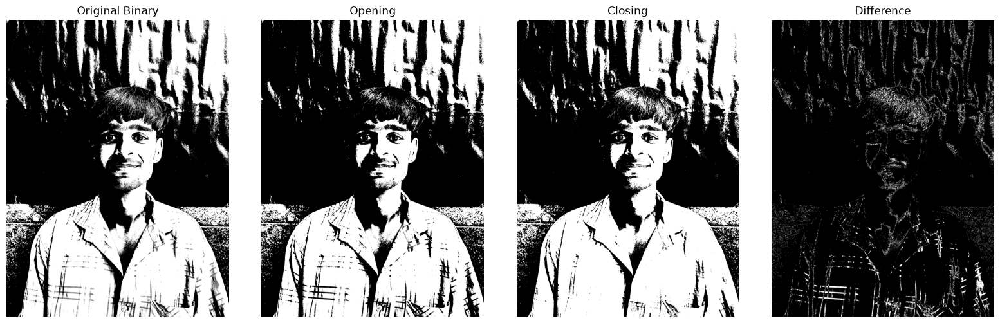

In [77]:
# Display the results
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(morph_binary, cmap="gray")
plt.title("Original Binary")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(opening_image, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(closing_image, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(cv2.absdiff(opening_image, closing_image), cmap="gray")
plt.title("Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

In [78]:
morphology_dir = (
    Path.cwd() / "processed_images" / "morphological_operations"
)
morphology_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(morphology_dir / "opening_image.jpg"),
    opening_image
)

cv2.imwrite(
    str(morphology_dir / "closing_image.jpg"),
    closing_image
)

cv2.imwrite(
    str(morphology_dir / "opening_closing_difference.jpg"),
    cv2.absdiff(opening_image, closing_image)
)

print("Opening and closing images saved successfully.")
print("Output directory:", morphology_dir)

Opening and closing images saved successfully.
Output directory: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\morphological_operations


### Observation

Opening and closing use the same structuring element but apply
erosion and dilation in different orders.

Opening can remove small white regions, while closing can fill
small black holes and gaps.

The effect depends on the binary image, kernel size, and number
of iterations. Excessive morphological processing may remove
useful details.

## 6.8 Morphological Gradient

The morphological gradient highlights boundaries in an image.

It is calculated by subtracting the eroded image from the dilated image.
The resulting image emphasizes transitions around foreground objects.

Morphological gradient can be useful for studying object boundaries
before contour detection and region-of-interest extraction.

In [79]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [80]:
# Convert the original image to grayscale
gradient_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [81]:
# Convert grayscale image to binary
_, gradient_binary = cv2.threshold(
    gradient_gray,
    127,
    255,
    cv2.THRESH_BINARY
)

In [82]:
# Create a 3x3 structuring element
kernel = np.ones((3, 3), np.uint8)

In [83]:
# Calculate morphological gradient
morph_gradient = cv2.morphologyEx(
    gradient_binary,
    cv2.MORPH_GRADIENT,
    kernel
)


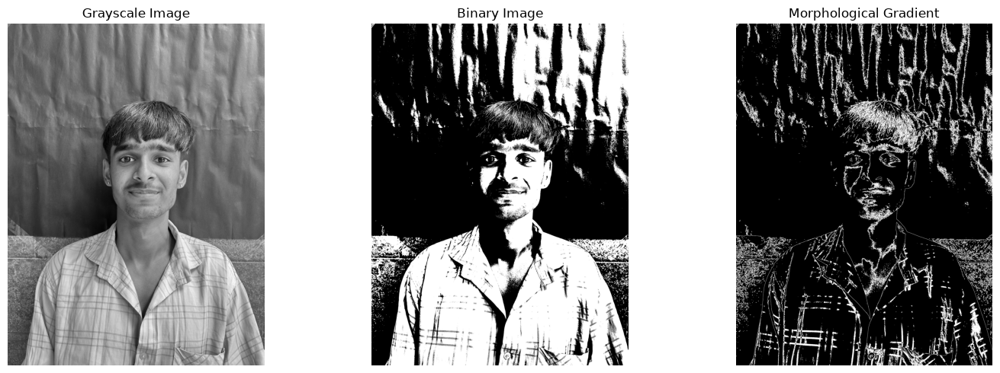

In [84]:
# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gradient_gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gradient_binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(morph_gradient, cmap="gray")
plt.title("Morphological Gradient")
plt.axis("off")

plt.tight_layout()
plt.show()

In [85]:
from pathlib import Path

morphology_dir = (
    Path.cwd() / "processed_images" / "morphological_operations"
)
morphology_dir.mkdir(parents=True, exist_ok=True)

gradient_path = morphology_dir / "morphological_gradient.jpg"

success = cv2.imwrite(str(gradient_path), morph_gradient)

if success:
    print("Morphological gradient saved:", gradient_path)
else:
    print("Error: Could not save the image.")

Morphological gradient saved: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\morphological_operations\morphological_gradient.jpg


 Formula: 
            Gradient = Dilation(I) - Erosion(I)

  Dilation: expands white regions.
  
  Erosion: shrinks white regions.
  
  Gradient: highlights the differences around region boundaries.

### Observation

The morphological gradient emphasizes boundaries by calculating
the difference between dilation and erosion.

The resulting image highlights transitions around binary regions.
Its appearance depends on the kernel and the threshold used to
create the binary image.

Morphological gradient highlights boundaries but does not identify
whether an object is a face, ear, or another structure.

# 7. UNIT 4 - Histogram Enhancement

## 7.1 Grayscale Histogram Analysis

A histogram represents the frequency of pixel intensity values
in an image.

For an 8-bit grayscale image, intensity values range from 0 to 255.
A value of 0 represents black, while 255 represents white.

Histogram analysis helps understand image brightness and contrast
before applying enhancement techniques.

In [4]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [5]:
PROJECT_ROOT = Path.cwd()
images_dir = PROJECT_ROOT / "Images"
front_dir = images_dir / "front"

In [6]:
# Find available front-view images
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

In [7]:
front_images = [
    p for p in front_dir.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
]

In [8]:
if not front_images:
    raise FileNotFoundError(
        f"No images found in: {front_dir}"
    )


In [9]:
# Load the original driver image
IMAGE_PATH = front_images[0]
image = cv2.imread(str(IMAGE_PATH))

In [10]:
if image is None:
    raise FileNotFoundError(
        f"Could not load image: {IMAGE_PATH}"
    )

In [11]:
print("Image loaded successfully!")
print("Image path:", IMAGE_PATH)
print("Image shape:", image.shape)

Image loaded successfully!
Image path: C:\Users\Admin\Desktop\DriverMonitoringSystem\Images\front\IMG_4159.JPG
Image shape: (4032, 3024, 3)


In [14]:
#hist equalization
# Convert the original image to grayscale
equalization_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [15]:
# Apply histogram equalization
equalized_image = cv2.equalizeHist(equalization_gray)

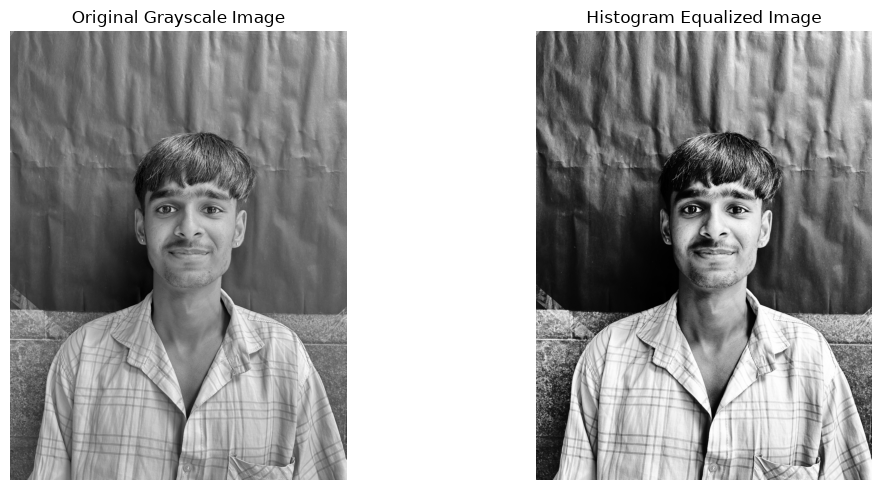

In [16]:
# Display both images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(equalization_gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
from pathlib import Path

In [18]:
histogram_dir = (
    Path.cwd() / "processed_images" / "histogram_enhancement"
)

In [19]:
histogram_dir.mkdir(parents=True, exist_ok=True)

In [20]:
save_path = histogram_dir / "histogram_equalized.jpg"

In [21]:
success = cv2.imwrite(str(save_path), equalized_image)


In [22]:
print("Saved successfully:", success)
print("File path:", save_path)

Saved successfully: True
File path: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\histogram_enhancement\histogram_equalized.jpg


Histogram equalization redistributes grayscale intensity values
to improve global image contrast.

It may make certain details more visible, but it can also amplify
noise or produce excessive contrast in some regions.

Contrast Limited Adaptive Histogram Equalization (CLAHE)

CLAHE is an image enhancement technique that improves local contrast.

Unlike standard histogram equalization, CLAHE divides an image into
small regions called tiles and applies histogram equalization locally.

It limits contrast amplification to reduce excessive enhancement
of noise in relatively uniform regions.

In [23]:
import cv2
import matplotlib.pyplot as plt

In [24]:
# Convert the original image to grayscale
clahe_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [25]:
# Create a CLAHE object
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

In [26]:
# Apply CLAHE
clahe_image = clahe.apply(clahe_gray)

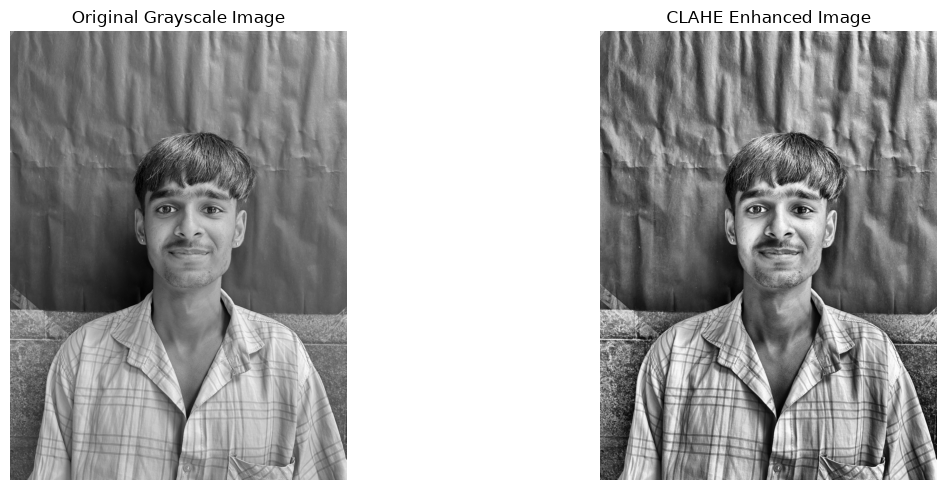

In [27]:
# Display the results
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(clahe_gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
#comparison of normal grayscale,hist equalized,and clahe images
equalized_image = cv2.equalizeHist(clahe_gray)


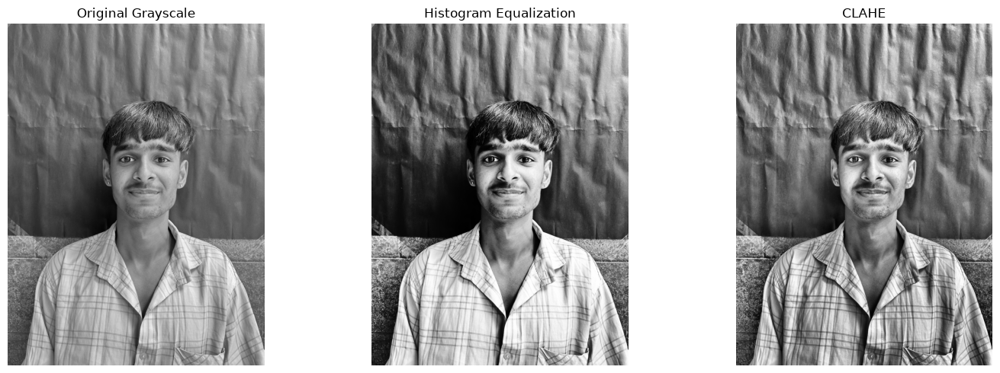

In [29]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(clahe_gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized_image, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_image, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path

histogram_dir = (
    Path.cwd() / "processed_images" / "histogram_enhancement"
)
histogram_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(histogram_dir / "clahe_enhanced.jpg"),
    clahe_image
)

cv2.imwrite(
    str(histogram_dir / "histogram_equalized.jpg"),
    equalized_image
)

print("CLAHE and histogram equalization results saved.")
print("Output directory:", histogram_dir)

CLAHE and histogram equalization results saved.
Output directory: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\histogram_enhancement


In [33]:
#comparison of all three intensity histograms
plt.figure(figsize=(15, 5))

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

In [34]:
images_to_compare = [
    ("Original Grayscale", comparison_gray),
    ("Histogram Equalization", comparison_equalized),
    ("CLAHE", comparison_clahe)
]


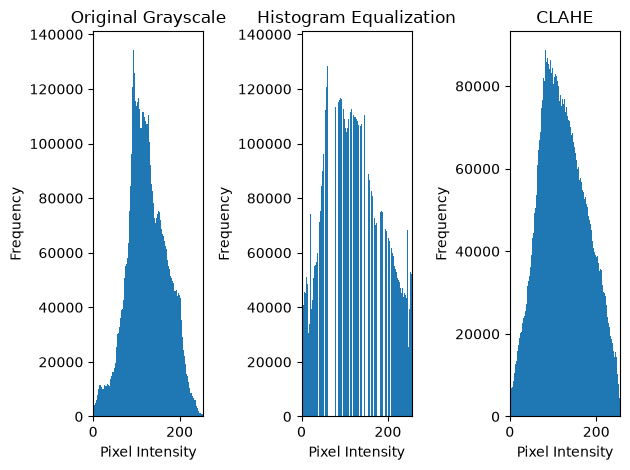

In [37]:
for index, (title, img) in enumerate(images_to_compare, start=1):
    plt.subplot(1, 3, index)

    plt.hist(
        img.ravel(),
        bins=256,
        range=(0, 256)
    )

    plt.title(title)
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.xlim(0, 255)

plt.tight_layout()
plt.show()

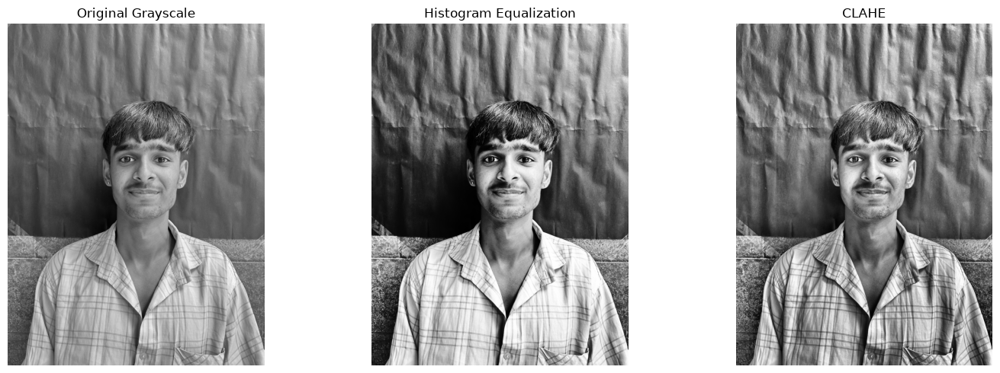

All comparison images saved successfully.
Output directory: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\histogram_enhancement
Comparison figure: C:\Users\Admin\Desktop\DriverMonitoringSystem\processed_images\histogram_enhancement\enhancement_comparison.png


In [40]:
#saving comparison results
histogram_dir = (
    Path.cwd() / "processed_images" / "histogram_enhancement"
)
histogram_dir.mkdir(parents=True, exist_ok=True)

# Save enhanced images
cv2.imwrite(
    str(histogram_dir / "comparison_original_grayscale.jpg"),
    comparison_gray
)

cv2.imwrite(
    str(histogram_dir / "comparison_histogram_equalization.jpg"),
    comparison_equalized
)

cv2.imwrite(
    str(histogram_dir / "comparison_clahe.jpg"),
    comparison_clahe
)

# Save the comparison figure
comparison_path = histogram_dir / "enhancement_comparison.png"

plt.figure(figsize=(15, 5))

for index, (title, img) in enumerate(images_to_compare, start=1):
    plt.subplot(1, 3, index)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("All comparison images saved successfully.")
print("Output directory:", histogram_dir)
print("Comparison figure:", comparison_path)

### Observation

The original grayscale image represents the initial intensity
distribution of the driver image.

Histogram equalization redistributes intensities to improve global
contrast, whereas CLAHE enhances contrast locally while limiting
contrast amplification.

The visual results and image statistics differ depending on the
input image and enhancement parameters. Neither method guarantees
better visibility in every region.

The most suitable method should be selected by visually inspecting
the enhanced images and checking whether important driver details
remain visible without excessive noise.